# Phase 1: Preprocessing CICIDS2017 Dataset

In [3]:
import os
import glob
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [4]:
RAW_DIR = "/kaggle/input/datasets/sateeshkumar6289/cicids-2017-dataset"
OUT_DIR = "/kaggle/working/processed" 

In [5]:
#a new directory will be craete where we will stor the output dataset after cleaning it.
os.makedirs(OUT_DIR, exist_ok=True)

In [6]:
# STEP 1: Load and combine the CSV files
csv_paths = glob.glob(os.path.join(RAW_DIR, "*.csv"))
df_list = [pd.read_csv(path, low_memory=False, encoding="latin1") for path in csv_paths]
df = pd.concat(df_list)
df = df.reset_index(drop=True)
print("Combined shape:", df.shape)

Combined shape: (2830743, 79)


In [7]:
# STEP 2: Clean column names (strip stray whitespace)
df.columns = df.columns.str.strip()

In [8]:
# STEP 3: Identify the label column
label_col = "Label"
print("Label column:", label_col)
print(df[label_col].value_counts())#gives the total number rows which contains that attacks 


Label column: Label
Label
BENIGN                          2273097
DoS Hulk                         231073
PortScan                         158930
DDoS                             128027
DoS GoldenEye                     10293
FTP-Patator                        7938
SSH-Patator                        5897
DoS slowloris                      5796
DoS Slowhttptest                   5499
Bot                                1966
Web Attack ï¿½ Brute Force         1507
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


In [9]:
# STEP 4: Remove duplicate rows (before the split, to avoid the leakage)
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after dedup:", df.shape)

Duplicates: 308381
Shape after dedup: (2522362, 79)


In [10]:
# STEP 5: Handle infinite and missing values
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)
print("Rows with missing values:", df[numeric_cols].isna().any(axis=1).sum())
df = df.dropna(subset=numeric_cols)
print("Shape after dropping missing rows:", df.shape)

Rows with missing values: 1564
Shape after dropping missing rows: (2520798, 79)


In [11]:
# STEP 6: Drop identifier / leakage-risk columns becuse the 
#model will not learn from attack categories and will jsut memorise the dataset
id_cols = ["Flow ID", "Source IP", "Src IP", "Destination IP", "Dst IP", "Timestamp"]
df = df.drop(columns=[c for c in id_cols if c in df.columns])


In [12]:
# STEP 7: Drop constant (zero-variance) columns because they contribute nothing to the training
numeric_cols = df.select_dtypes(include=[np.number]).columns  # recompute after drops
constant_cols = [c for c in numeric_cols if df[c].nunique() <= 1]
df = df.drop(columns=constant_cols)
print("Dropped constant columns:", constant_cols)

Dropped constant columns: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [13]:
# STEP 8: Build the labels
# 2 kinds of lables
# 1. binary label: benign=0,maliciou=1
# 2. attack category: the specific attack
df[label_col] = df[label_col].astype(str).str.strip()
df["Binary_Label"] = (df[label_col] != "BENIGN").astype(int)
df["Attack_Category"] = df[label_col]
df = df.drop(columns=[label_col])
print("\nClass distribution:")
print(df["Attack_Category"].value_counts())
#the below data shows each attack category occupies how many rows in the datset


Class distribution:
Attack_Category
BENIGN                          2095057
DoS Hulk                         172846
DDoS                             128014
PortScan                          90694
DoS GoldenEye                     10286
FTP-Patator                        5931
DoS slowloris                      5385
DoS Slowhttptest                   5228
SSH-Patator                        3219
Bot                                1948
Web Attack ï¿½ Brute Force         1470
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


In [14]:
# STEP 9: Separate features/labels, then train/test split
feature_cols = [c for c in df.columns if c not in ("Binary_Label", "Attack_Category")]
X = df[feature_cols]
y = df["Binary_Label"]

X_train, X_test, y_train, y_test, cat_train, cat_test = train_test_split(
    X, y, df["Attack_Category"],
    test_size=0.2,
    random_state=42,
    stratify=y,
)
print("Train rows:", X_train.shape[0], "| Test rows:", X_test.shape[0])


Train rows: 2016638 | Test rows: 504160


In [15]:
# STEP 10: Scale features (fit on train only, apply to test)
# we are scaling here becuase one column may be in millions and the other is represented using only number
#if there is a huge diffrence in the numbers then the model will get confused
#that is why we just scale to some similar avalues 
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=feature_cols)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_cols)

In [16]:

# STEP 11: Save processed data
X_train_scaled["Binary_Label"] = y_train.values
X_train_scaled["Attack_Category"] = cat_train.values

X_test_scaled["Binary_Label"] = y_test.values
X_test_scaled["Attack_Category"] = cat_test.values

X_train_scaled.to_csv(os.path.join(OUT_DIR, "train.csv"), index=False)
X_test_scaled.to_csv(os.path.join(OUT_DIR, "test.csv"), index=False)

print("\nSaved train.csv and test.csv to", OUT_DIR)


Saved train.csv and test.csv to /kaggle/working/processed


In [17]:
import os

for root, dirs, files in os.walk("/kaggle/working"):
    for f in files:
        if f.endswith(".csv"):
            print(os.path.join(root, f))

/kaggle/working/processed/test.csv
/kaggle/working/processed/train.csv


# Phase 2: EDA 

In [18]:
#Exploratory traffic analysis : to knwo about how dat is distributed
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


TRAIN_FILE = "/kaggle/working/processed/train.csv"


# Load the preprocessed training data
df = pd.read_csv(TRAIN_FILE)
print("Loaded data with shape:", df.shape)
print()

Loaded data with shape: (2016638, 72)



In [19]:
# PART 1: Class distribution - how imbalanced is the data?
print("=" * 60)
print("PART 1: Class Distribution")
print("=" * 60)

# Count how many Normal (0) vs Attack (1) rows we have
binary_counts = df["Binary_Label"].value_counts()
print("\nNormal vs Attack counts:")
print(binary_counts)

# Show the same thing as a percentage, easier to understand imbalance
binary_percent = df["Binary_Label"].value_counts(normalize=True) * 100
print("\nNormal vs Attack percentage:")
print(binary_percent.round(2))

# Count each individual attack category too
print("\nCounts per attack category:")
print(df["Attack_Category"].value_counts())

# Make a simple bar chart of attack categories
plt.figure(figsize=(10, 5))
df["Attack_Category"].value_counts().plot(kind="bar")
plt.title("Number of Flows per Attack Category")
plt.ylabel("Number of flows")
plt.xlabel("Category")
plt.tight_layout()
plt.savefig("class_distribution.png")
plt.close()
print("\nSaved chart: class_distribution.png")
#from the output you can see that 83% is normal data and the other nearly 17% is attack category. this shows class imbalance

PART 1: Class Distribution

Normal vs Attack counts:
Binary_Label
0    1676045
1     340593
Name: count, dtype: int64

Normal vs Attack percentage:
Binary_Label
0    83.11
1    16.89
Name: proportion, dtype: float64

Counts per attack category:
Attack_Category
BENIGN                          1676045
DoS Hulk                         138165
DDoS                             102382
PortScan                          72508
DoS GoldenEye                      8318
FTP-Patator                        4802
DoS slowloris                      4284
DoS Slowhttptest                   4242
SSH-Patator                        2584
Bot                                1564
Web Attack ï¿½ Brute Force         1157
Web Attack ï¿½ XSS                  533
Infiltration                         30
Web Attack ï¿½ Sql Injection         16
Heartbleed                            8
Name: count, dtype: int64

Saved chart: class_distribution.png


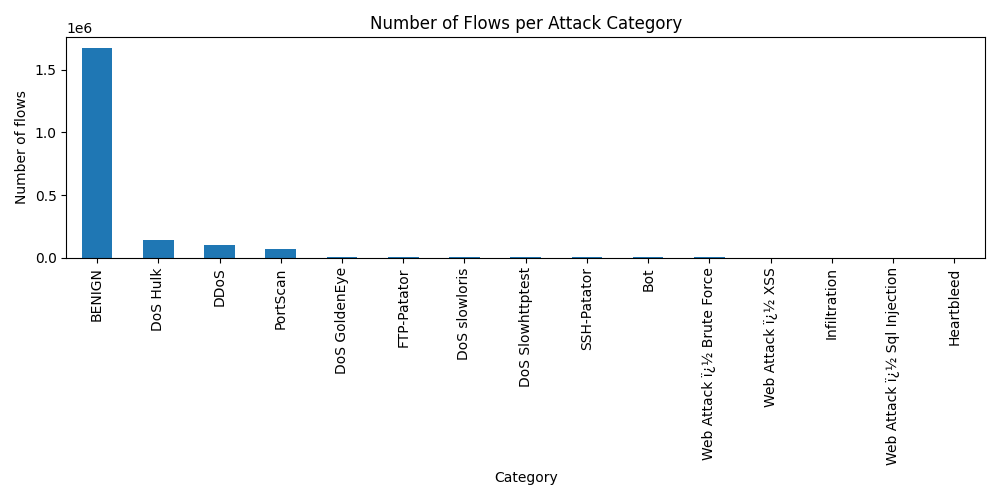

In [22]:
from IPython.display import Image, display
display(Image("/kaggle/working/class_distribution.png"))

In [23]:
  import os
  print(os.listdir("/kaggle/working"))

['processed', '.virtual_documents', 'class_distribution.png']


In [20]:
# PART 2: Compare a few key features between Normal and Attack traffic
print("\n" + "=" * 60)
print("PART 2: Normal vs Attack - Feature Comparison")
print("=" * 60)

# Pick a small number of important features to look at.

features_to_check = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
]

# keep only the features that actually exist in this dataset
features_to_check = [f for f in features_to_check if f in df.columns]
print("\nFeatures being compared:", features_to_check)
# For each feature, print the average value for Normal vs Attack rows
for feature in features_to_check:
    normal_avg = df[df["Binary_Label"] == 0][feature].mean()
    attack_avg = df[df["Binary_Label"] == 1][feature].mean()
    print(f"\n{feature}:")
    print(f"   Normal average: {normal_avg:.4f}")
    print(f"   Attack average: {attack_avg:.4f}")

# Now make a boxplot for each feature, comparing Normal vs Attack side by side
for feature in features_to_check:
    plt.figure(figsize=(6, 4))
    df.boxplot(column=feature, by="Binary_Label")
    plt.title(f"{feature}: Normal (0) vs Attack (1)")
    plt.suptitle("")  # removes the default ugly subtitle
    plt.xlabel("Binary_Label (0 = Normal, 1 = Attack)")
    plt.ylabel(feature)
    plt.tight_layout()
    safe_name = feature.replace("/", "_").replace(" ", "_")
    plt.savefig(f"boxplot_{safe_name}.png")
    plt.close()

print("\nSaved one boxplot image per feature (boxplot_<feature>.png)")



PART 2: Normal vs Attack - Feature Comparison

Features being compared: ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Flow Bytes/s', 'Flow Packets/s']

Flow Duration:
   Normal average: -0.1256
   Attack average: 0.6182

Total Fwd Packets:
   Normal average: 0.0014
   Attack average: -0.0069

Total Backward Packets:
   Normal average: 0.0015
   Attack average: -0.0072

Flow Bytes/s:
   Normal average: 0.0100
   Attack average: -0.0491

Flow Packets/s:
   Normal average: 0.0309
   Attack average: -0.1522

Saved one boxplot image per feature (boxplot_<feature>.png)


<Figure size 600x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>

In [25]:
import os
print(os.listdir("/kaggle/working"))

['boxplot_Total_Backward_Packets.png', 'boxplot_Flow_Bytes_s.png', 'processed', 'boxplot_Total_Fwd_Packets.png', '.virtual_documents', 'boxplot_Flow_Duration.png', 'boxplot_Flow_Packets_s.png', 'class_distribution.png']


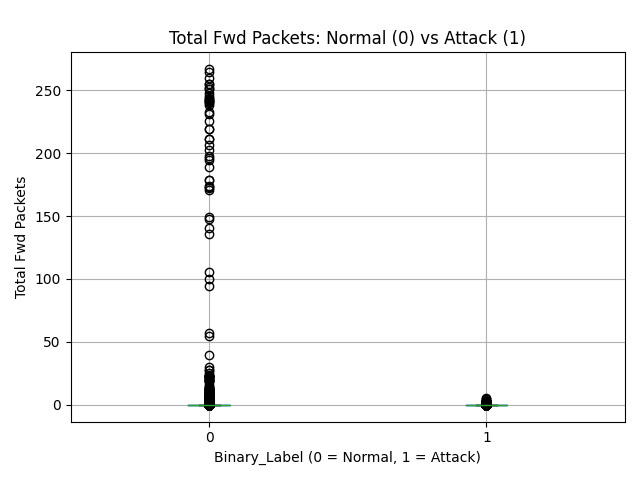

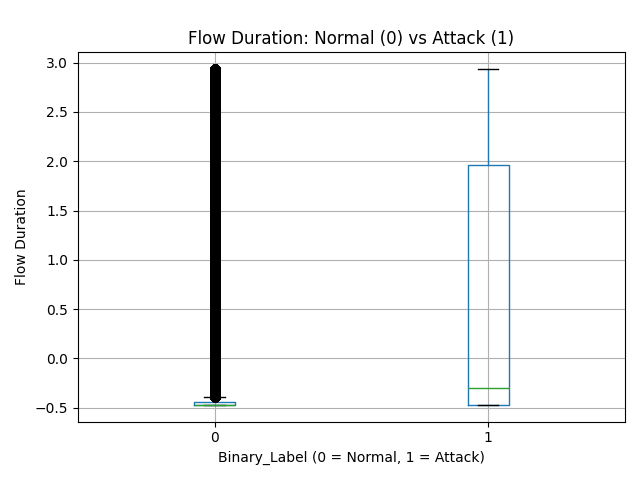

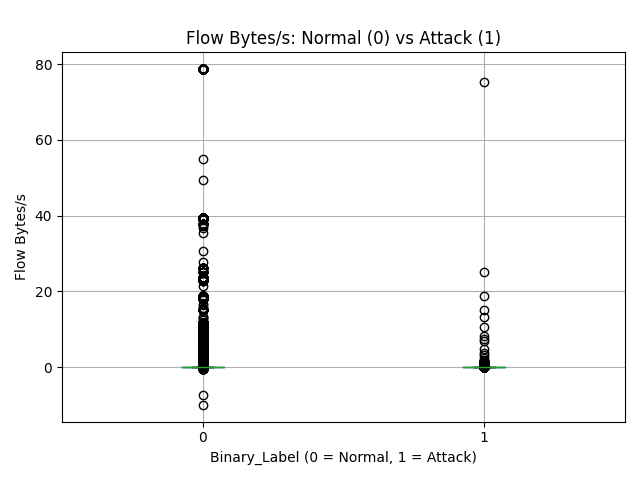

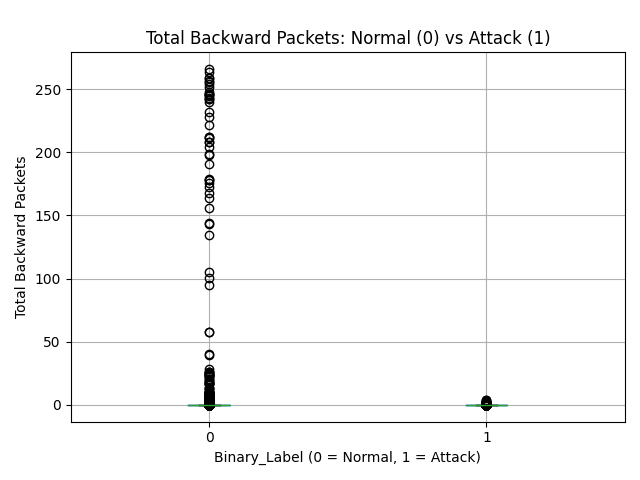

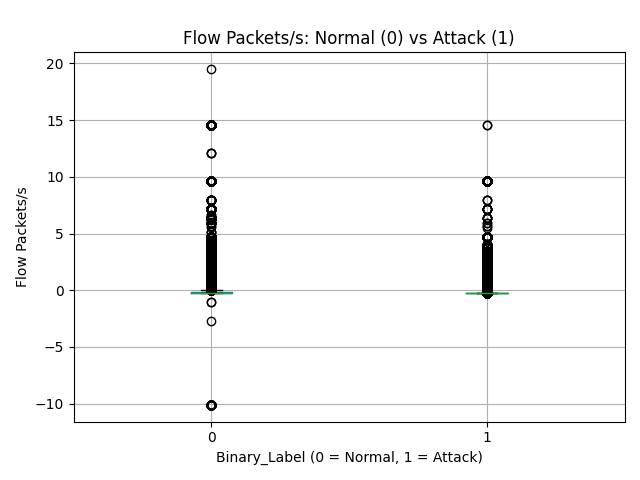

In [26]:
from IPython.display import Image, display
display(Image("/kaggle/working/boxplot_Total_Fwd_Packets.png"))
display(Image("/kaggle/working/boxplot_Flow_Duration.png"))
display(Image("/kaggle/working/boxplot_Flow_Bytes_s.png"))
display(Image("/kaggle/working/boxplot_Total_Backward_Packets.png"))
display(Image("/kaggle/working/boxplot_Flow_Packets_s.png"))

In [21]:
# PART 3: Compare features ACROSS different attack categories
print("\n" + "=" * 60)
print("PART 3: Comparing Attack Categories to Each Other")
print("=" * 60)

# We take the top 5 most common categories (this usually includes BENIGN).
top_categories = df["Attack_Category"].value_counts().head(6).index.tolist()
print("\nTop categories being compared:", top_categories)

df_top = df[df["Attack_Category"].isin(top_categories)]

for feature in features_to_check:
    plt.figure(figsize=(8, 5))
    df_top.boxplot(column=feature, by="Attack_Category", rot=45)
    plt.title(f"{feature} across top attack categories")
    plt.suptitle("")
    plt.ylabel(feature)
    plt.tight_layout()
    safe_name = feature.replace("/", "_").replace(" ", "_")
    plt.savefig(f"category_boxplot_{safe_name}.png")
    plt.close()

print("\nSaved one boxplot per feature comparing categories (category_boxplot_<feature>.png)")


PART 3: Comparing Attack Categories to Each Other

Top categories being compared: ['BENIGN', 'DoS Hulk', 'DDoS', 'PortScan', 'DoS GoldenEye', 'FTP-Patator']

Saved one boxplot per feature comparing categories (category_boxplot_<feature>.png)


<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

In [28]:
import os
print(os.listdir("/kaggle/working"))

['boxplot_Total_Backward_Packets.png', 'category_boxplot_Flow_Packets_s.png', 'boxplot_Flow_Bytes_s.png', 'processed', 'boxplot_Total_Fwd_Packets.png', 'category_boxplot_Flow_Bytes_s.png', '.virtual_documents', 'boxplot_Flow_Duration.png', 'category_boxplot_Total_Backward_Packets.png', 'boxplot_Flow_Packets_s.png', 'class_distribution.png', 'category_boxplot_Total_Fwd_Packets.png', 'category_boxplot_Flow_Duration.png']


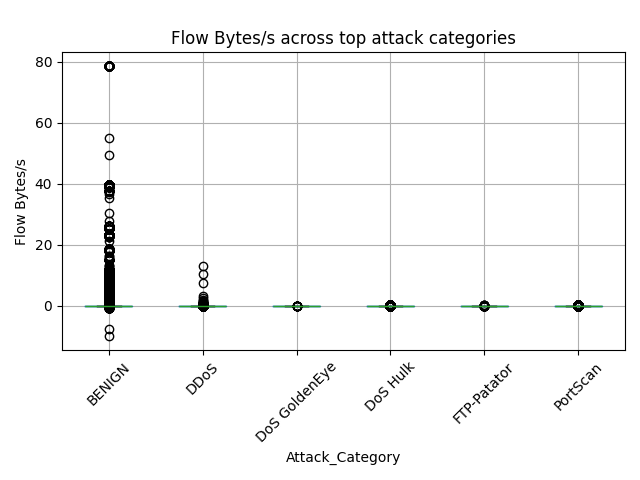

In [29]:
from IPython.display import Image, display
display(Image("/kaggle/working/category_boxplot_Flow_Bytes_s.png"))

In [22]:
# PART 4: Correlation heatmap - find features that repeat the same info
print("\n" + "=" * 60)
print("PART 4: Correlation Between Features")
print("=" * 60)

# Only use numeric columns, and exclude the label columns
numeric_df = df.select_dtypes(include=[np.number])
numeric_df = numeric_df.drop(columns=["Binary_Label"], errors="ignore")

# To keep the heatmap readable, only look at the first 20 numeric columns
columns_to_plot = numeric_df.columns[:20]
correlation_matrix = numeric_df[columns_to_plot].corr()

plt.figure(figsize=(12, 10))
plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(columns_to_plot)), columns_to_plot, rotation=90)
plt.yticks(range(len(columns_to_plot)), columns_to_plot)
plt.title("Correlation Heatmap (first 20 numeric features)")
plt.tight_layout()
plt.savefig("correlation_heatmap.png")
plt.close()
print("\nSaved chart: correlation_heatmap.png")

# Print out any pair of features that are VERY highly correlated (>0.9)
print("\nHighly correlated feature pairs (correlation > 0.9):")
already_shown = set()
for col1 in correlation_matrix.columns:
    for col2 in correlation_matrix.columns:
        if col1 != col2:
            pair = tuple(sorted([col1, col2]))
            corr_value = correlation_matrix.loc[col1, col2]
            if abs(corr_value) > 0.9 and pair not in already_shown:
                print(f"   {col1}  <->  {col2}   correlation = {corr_value:.2f}")
                already_shown.add(pair)



PART 4: Correlation Between Features

Saved chart: correlation_heatmap.png

Highly correlated feature pairs (correlation > 0.9):
   Total Fwd Packets  <->  Total Backward Packets   correlation = 1.00
   Total Fwd Packets  <->  Total Length of Bwd Packets   correlation = 1.00
   Total Backward Packets  <->  Total Length of Bwd Packets   correlation = 0.99
   Fwd Packet Length Max  <->  Fwd Packet Length Std   correlation = 0.97
   Bwd Packet Length Max  <->  Bwd Packet Length Mean   correlation = 0.96
   Bwd Packet Length Max  <->  Bwd Packet Length Std   correlation = 0.98
   Bwd Packet Length Mean  <->  Bwd Packet Length Std   correlation = 0.94
   Flow IAT Std  <->  Flow IAT Max   correlation = 0.94


In [23]:

# PART 5: Check if any feature separates Attack vs Normal TOO perfectly
print("\n" + "=" * 60)
print("PART 5: Checking for Suspiciously Perfect Features")
print("=" * 60)
print("If a feature separates Normal/Attack almost perfectly, investigate")
print("why - it might be a real signal, or a data collection artifact.\n")

for feature in features_to_check:
    normal_values = df[df["Binary_Label"] == 0][feature]
    attack_values = df[df["Binary_Label"] == 1][feature]

    normal_max = normal_values.max()
    normal_min = normal_values.min()
    attack_max = attack_values.max()
    attack_min = attack_values.min()

    # If the value ranges for Normal and Attack don't overlap at all,
    # this feature ALONE can perfectly tell them apart - worth investigating.
    no_overlap = (normal_max < attack_min) or (attack_max < normal_min)

    print(f"{feature}:")
    print(f"   Normal range: {normal_min:.2f} to {normal_max:.2f}")
    print(f"   Attack range: {attack_min:.2f} to {attack_max:.2f}")
    if no_overlap:
        print("   WARNING: ranges do not overlap at all - investigate this feature!")
    print()

print("Done with Phase 2. Check the saved .png images in this folder.")


PART 5: Checking for Suspiciously Perfect Features
If a feature separates Normal/Attack almost perfectly, investigate
why - it might be a real signal, or a data collection artifact.

Flow Duration:
   Normal range: -0.47 to 2.93
   Attack range: -0.47 to 2.93

Total Fwd Packets:
   Normal range: -0.01 to 266.80
   Attack range: -0.01 to 5.30

Total Backward Packets:
   Normal range: -0.01 to 265.90
   Attack range: -0.01 to 3.97

Flow Bytes/s:
   Normal range: -9.97 to 78.67
   Attack range: -0.05 to 75.21

Flow Packets/s:
   Normal range: -10.10 to 19.50
   Attack range: -0.23 to 14.57

Done with Phase 2. Check the saved .png images in this folder.


In [32]:
import os
print(os.listdir("/kaggle/working"))

['boxplot_Total_Backward_Packets.png', 'category_boxplot_Flow_Packets_s.png', 'boxplot_Flow_Bytes_s.png', 'processed', 'boxplot_Total_Fwd_Packets.png', 'category_boxplot_Flow_Bytes_s.png', '.virtual_documents', 'correlation_heatmap.png', 'boxplot_Flow_Duration.png', 'category_boxplot_Total_Backward_Packets.png', 'boxplot_Flow_Packets_s.png', 'class_distribution.png', 'category_boxplot_Total_Fwd_Packets.png', 'category_boxplot_Flow_Duration.png']


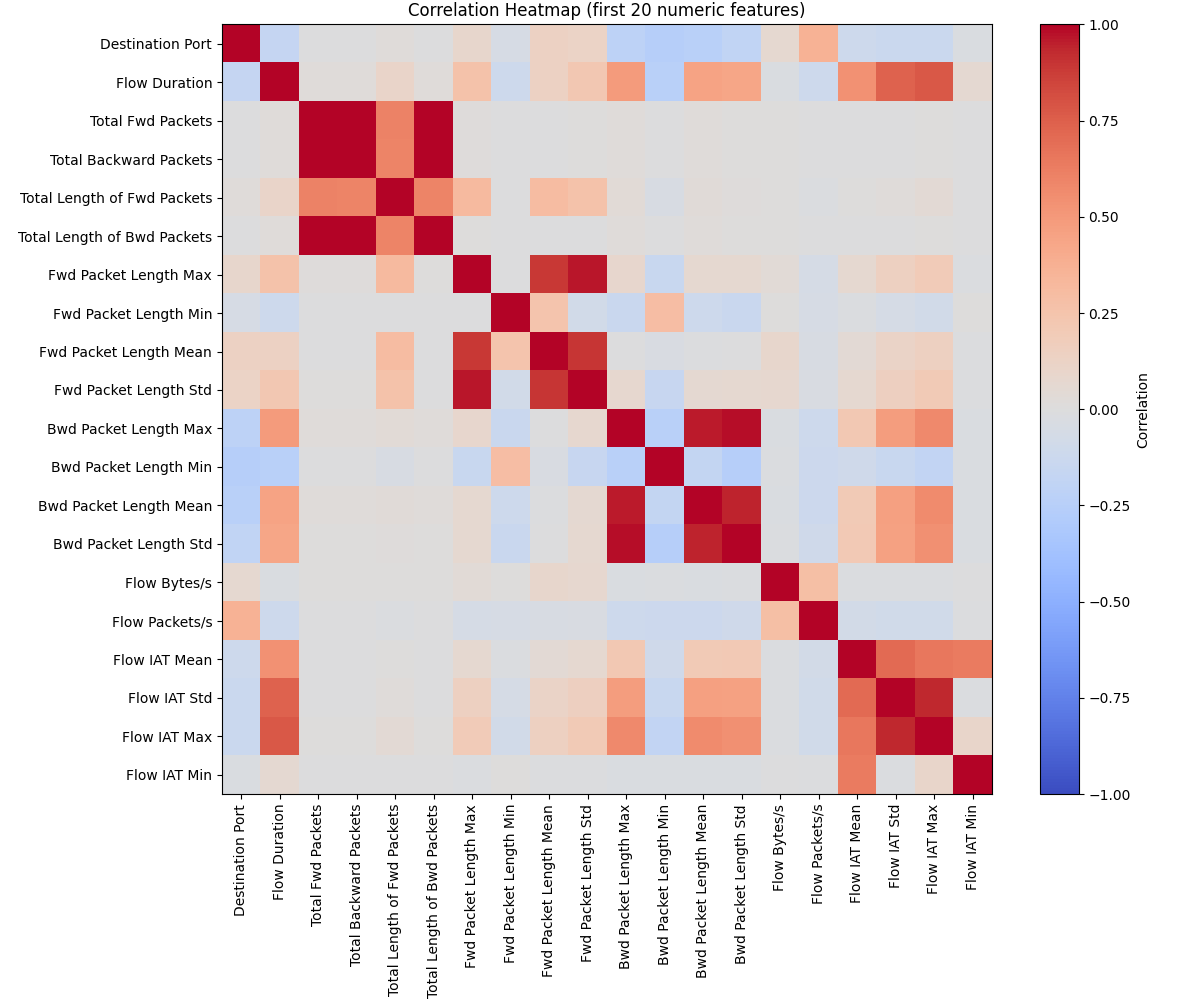

In [33]:
from IPython.display import Image, display
display(Image("/kaggle/working/correlation_heatmap.png"))

In [34]:
import os
print(os.listdir("."))

['boxplot_Total_Backward_Packets.png', 'category_boxplot_Flow_Packets_s.png', 'boxplot_Flow_Bytes_s.png', 'processed', 'boxplot_Total_Fwd_Packets.png', 'category_boxplot_Flow_Bytes_s.png', '.virtual_documents', 'correlation_heatmap.png', 'boxplot_Flow_Duration.png', 'category_boxplot_Total_Backward_Packets.png', 'boxplot_Flow_Packets_s.png', 'class_distribution.png', 'category_boxplot_Total_Fwd_Packets.png', 'category_boxplot_Flow_Duration.png']


# Phase 3: Training the models

In [24]:
import pandas as pd
import numpy as np
import time
 
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
 
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    classification_report,
)


 
TRAIN_FILE = "/kaggle/working/processed/train.csv"
TEST_FILE = "/kaggle/working/processed/test.csv"
 

In [25]:
# STEP 1: Load the preprocessed train and test data
train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
 
# STEP 2: Separate features (X) from the target (y)
# We only need Binary_Label for this phase - Attack_Category is for Phase 4
columns_to_drop = ["Binary_Label", "Attack_Category"]
 
X_train = train_df.drop(columns=columns_to_drop)
y_train = train_df["Binary_Label"]
 
X_test = test_df.drop(columns=columns_to_drop)
y_test = test_df["Binary_Label"]
 
print("Number of features used:", X_train.shape[1])

Train shape: (2016638, 72)
Test shape: (504160, 72)
Number of features used: 70


In [26]:
#STEP 3: A helper function that trains one model and prints ALL the
# security-relevant metrics your project guide asks for.
def train_and_evaluate(model, model_name, X_train, y_train, X_test, y_test):
    print("\n" + "=" * 60)
    print("MODEL:", model_name)
    print("=" * 60)
 
    #  Train the model, and time how long it takes 
    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time
 
    # Predict on the test set, and time this too 
    start_time = time.time()
    y_pred = model.predict(X_test)
    prediction_time = time.time() - start_time
 
    # Get predicted probabilities (needed for ROC-AUC) 
    # predict_proba gives two columns: [probability of 0, probability of 1]
    # we only want the probability of class 1 (Attack)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
 
    #  Core metrics
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_proba)
 
    #  Confusion matrix
    # This gives us: true negatives, false positives, false negatives, true positives
    cm = confusion_matrix(y_test, y_pred)
    true_negative, false_positive, false_negative, true_positive = cm.ravel()
 
    # False Positive Rate
    # FPR = how many Normal flows were wrongly flagged as attacks
    # out of ALL the actual Normal flows
    false_positive_rate = false_positive / (false_positive + true_negative)
 
    # Print everything 
    print(f"Training time:      {training_time:.2f} seconds")
    print(f"Prediction time:     {prediction_time:.4f} seconds")
    print(f"Precision:           {precision:.4f}")
    print(f"Recall:              {recall:.4f}  (this is your attack detection rate)")
    print(f"F1-score:            {f1:.4f}")
    print(f"False Positive Rate: {false_positive_rate:.4f}")
    print(f"ROC-AUC:             {roc_auc:.4f}")
 
    print("\nConfusion Matrix:")
    print("                  Predicted Normal   Predicted Attack")
    print(f"Actual Normal        {true_negative:>10}         {false_positive:>10}")
    print(f"Actual Attack        {false_negative:>10}         {true_positive:>10}")
 
    print("\nFull classification report:")
    print(classification_report(y_test, y_pred, target_names=["Normal", "Attack"]))
 
    # return the results so we can compare models at the end
    return {
        "model_name": model_name,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "false_positive_rate": false_positive_rate,
        "roc_auc": roc_auc,
        "training_time": training_time,
        "prediction_time": prediction_time,
    }
 
 

In [27]:
# STEP 4: Train and evaluate all three models
results = []
 
#  Model 1: Logistic Regression (simple baseline) 
log_reg_model = LogisticRegression(max_iter=1000)
results.append(
    train_and_evaluate(log_reg_model, "Logistic Regression", X_train, y_train, X_test, y_test)
)
 
# Model 2: Random Forest (tree-based baseline) 
random_forest_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
results.append(
    train_and_evaluate(random_forest_model, "Random Forest", X_train, y_train, X_test, y_test)
)
 
# ---- Model 3: XGBoost (primary model) ----
xgboost_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1,
)
results.append(
    train_and_evaluate(xgboost_model, "XGBoost", X_train, y_train, X_test, y_test)
)
 
 
# STEP 5: Put all results side by side so you can compare models easily
print("\n" + "=" * 60)
print("SUMMARY: All Models Compared")
print("=" * 60)
 
results_df = pd.DataFrame(results)
results_df = results_df.set_index("model_name")
print(results_df.round(4))
 
results_df.to_csv("phase3_model_comparison.csv")
print("\nSaved comparison table to: phase3_model_comparison.csv")
 
print("\nDone with Phase 3 baseline evaluation.")



MODEL: Logistic Regression
Training time:      96.06 seconds
Prediction time:     0.0854 seconds
Precision:           0.8819
Recall:              0.8619  (this is your attack detection rate)
F1-score:            0.8718
False Positive Rate: 0.0235
ROC-AUC:             0.9883

Confusion Matrix:
                  Predicted Normal   Predicted Attack
Actual Normal            409182               9830
Actual Attack             11756              73392

Full classification report:
              precision    recall  f1-score   support

      Normal       0.97      0.98      0.97    419012
      Attack       0.88      0.86      0.87     85148

    accuracy                           0.96    504160
   macro avg       0.93      0.92      0.92    504160
weighted avg       0.96      0.96      0.96    504160


MODEL: Random Forest
Training time:      433.12 seconds
Prediction time:     2.4708 seconds
Precision:           0.9964
Recall:              0.9948  (this is your attack detection rate)
F1-sco

# Phase 4: Multiclass Attack Classification

In [28]:
import pandas as pd
import numpy as np
 
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report
from xgboost import XGBClassifier



TRAIN_FILE = "/kaggle/working/processed/train.csv"
TEST_FILE = "/kaggle/working/processed/test.csv"

 
# STEP 1: Load the preprocessed data
train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (2016638, 72)
Test shape: (504160, 72)


In [29]:
print("\nCategory counts in training data:")
category_counts = train_df["Attack_Category"].value_counts()
print(category_counts)
 
# Set a minimum sample threshold. Categories with fewer training rows than
# this get EXCLUDED from multiclass training (they cannot be reliably
# learned or evaluated with so few examples).
MIN_SAMPLES = 50

 
categories_to_keep = category_counts[category_counts >= MIN_SAMPLES].index.tolist()
categories_dropped = category_counts[category_counts < MIN_SAMPLES].index.tolist()
 
print(f"\nKeeping {len(categories_to_keep)} categories with >= {MIN_SAMPLES} samples")
print("Categories kept:", categories_to_keep)
print("Categories dropped (too rare for reliable multiclass modelling):", categories_dropped)


Category counts in training data:
Attack_Category
BENIGN                          1676045
DoS Hulk                         138165
DDoS                             102382
PortScan                          72508
DoS GoldenEye                      8318
FTP-Patator                        4802
DoS slowloris                      4284
DoS Slowhttptest                   4242
SSH-Patator                        2584
Bot                                1564
Web Attack ï¿½ Brute Force         1157
Web Attack ï¿½ XSS                  533
Infiltration                         30
Web Attack ï¿½ Sql Injection         16
Heartbleed                            8
Name: count, dtype: int64

Keeping 12 categories with >= 50 samples
Categories kept: ['BENIGN', 'DoS Hulk', 'DDoS', 'PortScan', 'DoS GoldenEye', 'FTP-Patator', 'DoS slowloris', 'DoS Slowhttptest', 'SSH-Patator', 'Bot', 'Web Attack ï¿½ Brute Force', 'Web Attack ï¿½ XSS']
Categories dropped (too rare for reliable multiclass modelling): ['Infiltratio

In [30]:
train_filtered = train_df[train_df["Attack_Category"].isin(categories_to_keep)]
test_filtered = test_df[test_df["Attack_Category"].isin(categories_to_keep)]
 
print("\nTrain shape after filtering rare categories:", train_filtered.shape)
print("Test shape after filtering rare categories:", test_filtered.shape)
 
 
# STEP 4: Prepare features (X) and multiclass target (y)
columns_to_drop = ["Binary_Label", "Attack_Category"]
 
X_train = train_filtered.drop(columns=columns_to_drop)
X_test = test_filtered.drop(columns=columns_to_drop)
 
# XGBoost needs numeric labels, not text like "DDoS" or "BENIGN".
# LabelEncoder converts each category name into a number (0, 1, 2, ...)
label_encoder = LabelEncoder()
label_encoder.fit(train_filtered["Attack_Category"])
 
y_train = label_encoder.transform(train_filtered["Attack_Category"])
y_test = label_encoder.transform(test_filtered["Attack_Category"])
 
# Keep the mapping so we can turn numbers back into readable names later
class_names = label_encoder.classes_
print("\nClass number -> Category name mapping:")
for number, name in enumerate(class_names):
    print(f"   {number} -> {name}")
 
 
# STEP 5: Train the multiclass XGBoost model
print("\nTraining multiclass XGBoost model...")
 
multiclass_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="mlogloss",
    n_jobs=-1,
)
multiclass_model.fit(X_train, y_train)
 
y_pred = multiclass_model.predict(X_test)
print("Training complete.")


Train shape after filtering rare categories: (2016584, 72)
Test shape after filtering rare categories: (504146, 72)

Class number -> Category name mapping:
   0 -> BENIGN
   1 -> Bot
   2 -> DDoS
   3 -> DoS GoldenEye
   4 -> DoS Hulk
   5 -> DoS Slowhttptest
   6 -> DoS slowloris
   7 -> FTP-Patator
   8 -> PortScan
   9 -> SSH-Patator
   10 -> Web Attack ï¿½ Brute Force
   11 -> Web Attack ï¿½ XSS

Training multiclass XGBoost model...
Training complete.


In [31]:
#STEP 6: Multiclass confusion matrix
print("\n" + "=" * 60)
print("Multiclass Confusion Matrix")
print("=" * 60)
 
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
print(cm_df)
 
cm_df.to_csv("phase4_confusion_matrix.csv")
print("\nSaved confusion matrix to: phase4_confusion_matrix.csv")
"""
How to read this table:
Rows = the ACTUAL category
Columns = what the model PREDICTED
Numbers on the diagonal = correct predictions
Numbers off the diagonal = confusions (e.g. row=DDoS, column=BENIGN
means some real DDoS flows were predicted as BENIGN)
"""

# STEP 7: Per-class precision, recall, F1-score
print("\n" + "=" * 60)
print("Per-Class Performance")
print("=" * 60)
 
report_text = classification_report(y_test, y_pred, target_names=class_names)
print(report_text)
 
# Also save this as a proper table (easier to sort and inspect than plain text)
report_dict = classification_report(
    y_test, y_pred, target_names=class_names, output_dict=True
)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv("phase4_per_class_report.csv")
print("Saved per-class report to: phase4_per_class_report.csv")
 
 
# STEP 8: Highlight the best and worst detected categories
print("\n" + "=" * 60)
print("Best and Worst Detected Categories (by Recall)")
print("=" * 60)
 
# Only look at the actual class rows, not the summary rows
# (classification_report adds extra rows like "accuracy", "macro avg", etc.)
class_only_report = report_df.drop(
    index=[r for r in report_df.index if r not in class_names]
)
class_only_report = class_only_report.sort_values("recall", ascending=False)
 
print("\nBest detected categories (highest recall):")
print(class_only_report[["precision", "recall", "f1-score", "support"]].head(5))
 
print("\nWorst detected categories (lowest recall):")
print(class_only_report[["precision", "recall", "f1-score", "support"]].tail(5))
 
print("\nDone with Phase 4.")



Multiclass Confusion Matrix
                            BENIGN  Bot   DDoS  DoS GoldenEye  DoS Hulk  \
BENIGN                      418241   43     58             35       225   
Bot                            113  271      0              0         0   
DDoS                            46    0  25563              0        21   
DoS GoldenEye                   38    0      0           1926         2   
DoS Hulk                       263    0      4              6     34392   
DoS Slowhttptest                49    0      1             19         0   
DoS slowloris                   58    0      0              0         1   
FTP-Patator                     12    0      0              0         0   
PortScan                        17    0      5              0        11   
SSH-Patator                      4    0      0              0         0   
Web Attack ï¿½ Brute Force      28    0      0              0        10   
Web Attack ï¿½ XSS              14    0      0              0         5

In [32]:
import pandas as pd
import numpy as np
import gc

from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier
from imblearn.over_sampling import RandomOverSampler, SMOTE

# Check the number of samples in each class
class_counts = pd.Series(y_train).value_counts().sort_index()

distribution = pd.DataFrame({
    "Attack Category": label_encoder.classes_,
    "Training Samples": [
        class_counts.get(i, 0)
        for i in range(len(label_encoder.classes_))
    ]
})

print("Original training class distribution:")
print(distribution.to_string(index=False))

Original training class distribution:
           Attack Category  Training Samples
                    BENIGN           1676045
                       Bot              1564
                      DDoS            102382
             DoS GoldenEye              8318
                  DoS Hulk            138165
          DoS Slowhttptest              4242
             DoS slowloris              4284
               FTP-Patator              4802
                  PortScan             72508
               SSH-Patator              2584
Web Attack ï¿½ Brute Force              1157
        Web Attack ï¿½ XSS               533


In [33]:
# Target size for minority classes
TARGET_COUNT = 50000

# Find classes with fewer than 50,000 training samples
sampling_strategy = {
    class_id: TARGET_COUNT
    for class_id, count in class_counts.items()
    if count < TARGET_COUNT
}

print("Classes to oversample:")
for class_id, target_count in sampling_strategy.items():
    print(
        label_encoder.classes_[class_id],
        "->",
        target_count,
        "samples"
    )

# Use the same model settings for every experiment
def create_model():
    return XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        eval_metric="mlogloss",
        tree_method="hist",
        n_jobs=-1
    )


# Store overall results and individual class reports
results = []
class_reports = {}
confusion_matrices = {}


def evaluate_model(model, method_name):
    y_pred = model.predict(X_test)

    report = classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        output_dict=True,
        zero_division=0
    )

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(label_encoder.classes_))
    )

    results.append({
        "Method": method_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": report["macro avg"]["precision"],
        "Macro Recall": report["macro avg"]["recall"],
        "Macro F1": report["macro avg"]["f1-score"],
        "Weighted F1": report["weighted avg"]["f1-score"]
    })

    class_reports[method_name] = pd.DataFrame(report).T
    confusion_matrices[method_name] = pd.DataFrame(
        cm,
        index=label_encoder.classes_,
        columns=label_encoder.classes_
    )

    print("\n", "=" * 60)
    print(method_name)
    print("=" * 60)
    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    ))

    del y_pred, report, cm
    gc.collect()


# --------------------------------------------------
# EXPERIMENT 1: Original imbalanced training data
# --------------------------------------------------
print("\nExperiment 1: Original imbalanced data")

model = create_model()
model.fit(X_train, y_train)

evaluate_model(model, "Original")

del model
gc.collect()


# --------------------------------------------------
# EXPERIMENT 2: Class weighting
# --------------------------------------------------
print("\nExperiment 2: Class weighting")

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

model = create_model()
model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

evaluate_model(model, "Class Weighting")

del model, sample_weights
gc.collect()


# --------------------------------------------------
# EXPERIMENT 3: Random Oversampling
# --------------------------------------------------
print("\nExperiment 3: Random Oversampling")

ros = RandomOverSampler(
    sampling_strategy=sampling_strategy,
    random_state=42
)

X_ros, y_ros = ros.fit_resample(X_train, y_train)

print("Shape after Random Oversampling:", X_ros.shape)

model = create_model()
model.fit(X_ros, y_ros)

evaluate_model(model, "Random Oversampling")

del model, X_ros, y_ros, ros
gc.collect()


# --------------------------------------------------
# EXPERIMENT 4: SMOTE
# --------------------------------------------------
print("\nExperiment 4: SMOTE")

smote = SMOTE(
    sampling_strategy=sampling_strategy,
    random_state=42,
    k_neighbors=5
)

X_smote, y_smote = smote.fit_resample(X_train, y_train)

print("Shape after SMOTE:", X_smote.shape)

model = create_model()
model.fit(X_smote, y_smote)

evaluate_model(model, "SMOTE")

del model, X_smote, y_smote, smote
gc.collect()


print("\nAll four experiments completed.")

Classes to oversample:
Bot -> 50000 samples
DoS GoldenEye -> 50000 samples
DoS Slowhttptest -> 50000 samples
DoS slowloris -> 50000 samples
FTP-Patator -> 50000 samples
SSH-Patator -> 50000 samples
Web Attack ï¿½ Brute Force -> 50000 samples
Web Attack ï¿½ XSS -> 50000 samples

Experiment 1: Original imbalanced data

Original
                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00    419012
                       Bot       0.90      0.75      0.82       384
                      DDoS       1.00      1.00      1.00     25632
             DoS GoldenEye       0.99      1.00      0.99      1968
                  DoS Hulk       1.00      1.00      1.00     34681
          DoS Slowhttptest       0.99      0.99      0.99       986
             DoS slowloris       1.00      1.00      1.00      1101
               FTP-Patator       1.00      1.00      1.00      1129
                  PortScan       0.99      1.00      0.99  

In [34]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
)

print("Final Comparison:")
print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    "/kaggle/working/imbalance_comparison.csv",
    index=False
)

print("\nSaved to imbalance_comparison.csv")

Final Comparison:
             Method  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1
Random Oversampling    0.9987           0.9045        0.9388    0.9125       0.9987
              SMOTE    0.9986           0.9027        0.9392    0.9113       0.9987
           Original    0.9989           0.9197        0.8995    0.9024       0.9988
    Class Weighting    0.9978           0.8749        0.9361    0.8929       0.9980

Saved to imbalance_comparison.csv


In [35]:
best_method = results_df.iloc[0]["Method"]

print("Best method by Macro F1:", best_method)

print("\nPer-class results:")
print(
    class_reports[best_method][
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

print("\nConfusion matrix:")
print(confusion_matrices[best_method])

Best method by Macro F1: Random Oversampling

Per-class results:
                            precision  recall  f1-score      support
BENIGN                         0.9999  0.9989    0.9994  419012.0000
Bot                            0.6713  1.0000    0.8033     384.0000
DDoS                           0.9999  0.9997    0.9998   25632.0000
DoS GoldenEye                  0.9949  0.9980    0.9964    1968.0000
DoS Hulk                       0.9982  0.9997    0.9990   34681.0000
DoS Slowhttptest               0.9839  0.9909    0.9874     986.0000
DoS slowloris                  0.9937  0.9982    0.9959    1101.0000
FTP-Patator                    0.9991  1.0000    0.9996    1129.0000
PortScan                       0.9893  0.9994    0.9943   18186.0000
SSH-Patator                    1.0000  0.9969    0.9984     635.0000
Web Attack ï¿½ Brute Force     0.8498  0.5783    0.6882     313.0000
Web Attack ï¿½ XSS             0.3733  0.7059    0.4884     119.0000
accuracy                       0.9987 

# Feature selection:
using XGBoost model 

In [36]:
# Separate features (X) and target (y)

columns_to_drop = ["Binary_Label", "Attack_Category"]
 
X_train = train_filtered.drop(columns=columns_to_drop)
X_test = test_filtered.drop(columns=columns_to_drop)
label_encoder = LabelEncoder()
label_encoder.fit(train_filtered["Attack_Category"])
 
y_train = label_encoder.transform(train_filtered["Attack_Category"])
y_test = label_encoder.transform(test_filtered["Attack_Category"])
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (2016584, 70)
y_train shape: (2016584,)
X_test shape: (504146, 70)
y_test shape: (504146,)


In [37]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.feature_selection import SelectFromModel

# X = input features
# y = target/label

# Create XGBoost model
model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

# Train the model
model.fit(X_train, y_train)

# Select features based on importance
#let us say we have 80 features then XGBOost will give some importnace value to each one of them and we dont know which one to take
#and that is why we compute the median and if the imporatnce lies above this median then we are going to kepp that feature
selector = SelectFromModel(
    model,
    threshold="median",
    prefit=True
)

# Transform X
X_selected = selector.transform(X_train)

# Get names of selected features
selected_columns = X_train.columns[selector.get_support()]

print("Original number of features:", X_train.shape[1])
print("Selected number of features:", X_selected.shape[1])

print("\nSelected features:")
print(selected_columns.tolist())
#next print out the dropped features
dropped_features = X_train.columns.difference(selected_columns)
print("Number of dropped features: ",len(dropped_features))
print(dropped_features.tolist())

#next do the class imbalancing and then do feature selection beacsue feature slection with XG Boost depends on the distribution of data


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


Original number of features: 70
Selected number of features: 35

Selected features:
['Destination Port', 'Flow Duration', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Std', 'Fwd IAT Min', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Min Packet Length', 'Max Packet Length', 'FIN Flag Count', 'PSH Flag Count', 'Average Packet Size', 'Init_Win_bytes_backward', 'act_data_pkt_fwd', 'min_seg_size_forward', 'Active Mean', 'Active Std', 'Idle Mean', 'Idle Min']
Number of dropped features:  35
['ACK Flag Count', 'Active Max', 'Active Min', 'Avg Bwd Segment Size', 'Avg Fwd Segment Size', 'Bwd IAT Max', 'Bwd IAT Total', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet

In [38]:
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score
import numpy as np
import pandas as pd
import gc

# Use the selected features from feature selection
X_train_selected = X_train[selected_columns]
X_test_selected = X_test[selected_columns]

print("Original number of features:", X_train.shape[1])
print("Selected number of features:", X_train_selected.shape[1])

# Oversample training data only
class_counts = pd.Series(y_train).value_counts()

sampling_strategy = {
    cls: 50000
    for cls, count in class_counts.items()
    if count < 50000
}

smote = SMOTE(
    sampling_strategy=sampling_strategy,
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_selected, y_train
)

print("Training shape after SMOTE:", X_train_smote.shape)

# Train XGBoost
model_selected = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1
)

model_selected.fit(X_train_smote, y_train_smote)

# Evaluate on the original, unchanged test data
y_pred_selected = model_selected.predict(X_test_selected)

print("\nClassification Report - Selected Features")
print(classification_report(
    y_test,
    y_pred_selected,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

print("Accuracy:", accuracy_score(y_test, y_pred_selected))
print("Macro F1:", f1_score(
    y_test, y_pred_selected, average="macro"
))
print("Weighted F1:", f1_score(
    y_test, y_pred_selected, average="weighted"
))

# Release the large resampled arrays
del X_train_smote, y_train_smote
gc.collect()

Original number of features: 70
Selected number of features: 35
Training shape after SMOTE: (2389100, 35)

Classification Report - Selected Features
                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00    419012
                       Bot       0.29      0.99      0.45       384
                      DDoS       1.00      1.00      1.00     25632
             DoS GoldenEye       0.99      0.99      0.99      1968
                  DoS Hulk       1.00      0.99      1.00     34681
          DoS Slowhttptest       0.99      0.99      0.99       986
             DoS slowloris       1.00      1.00      1.00      1101
               FTP-Patator       1.00      1.00      1.00      1129
                  PortScan       0.99      1.00      0.99     18186
               SSH-Patator       1.00      1.00      1.00       635
Web Attack ï¿½ Brute Force       0.82      0.55      0.66       313
        Web Attack ï¿½ XSS       0

25

In [56]:
%whos

Variable                 Type                      Data/Info
------------------------------------------------------------
Image                    type                      <class 'IPython.core.display.Image'>
LabelEncoder             type                      <class 'sklearn.preproces<...>ing._label.LabelEncoder'>
LogisticRegression       type                      <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
MIN_SAMPLES              int                       50
OUT_DIR                  str                       /kaggle/working/processed
RAW_DIR                  str                       /kaggle/input/datasets/sa<...>r6289/cicids-2017-dataset
RandomForestClassifier   ABCMeta                   <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
RandomOverSampler        ABCMeta                   <class 'imblearn.over_sam<...>mpler.RandomOverSampler'>
SMOTE                    ABCMeta                   <class 'imblearn.over_sam<...>pling._smote.base.SMOTE'>
SelectFromModel  

In [58]:
!pip install shap

In [39]:
import shap
import matplotlib.pyplot as plt
import numpy as np

print("SHAP version:", shap.__version__)

SHAP version: 0.51.0


In [40]:
# Take a small sample from the test set
X_sample = X_test_selected.sample(
    n=500,
    random_state=42
)

# Create SHAP explainer
explainer = shap.TreeExplainer(model_selected)

# Calculate SHAP values
shap_values = explainer.shap_values(X_sample)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


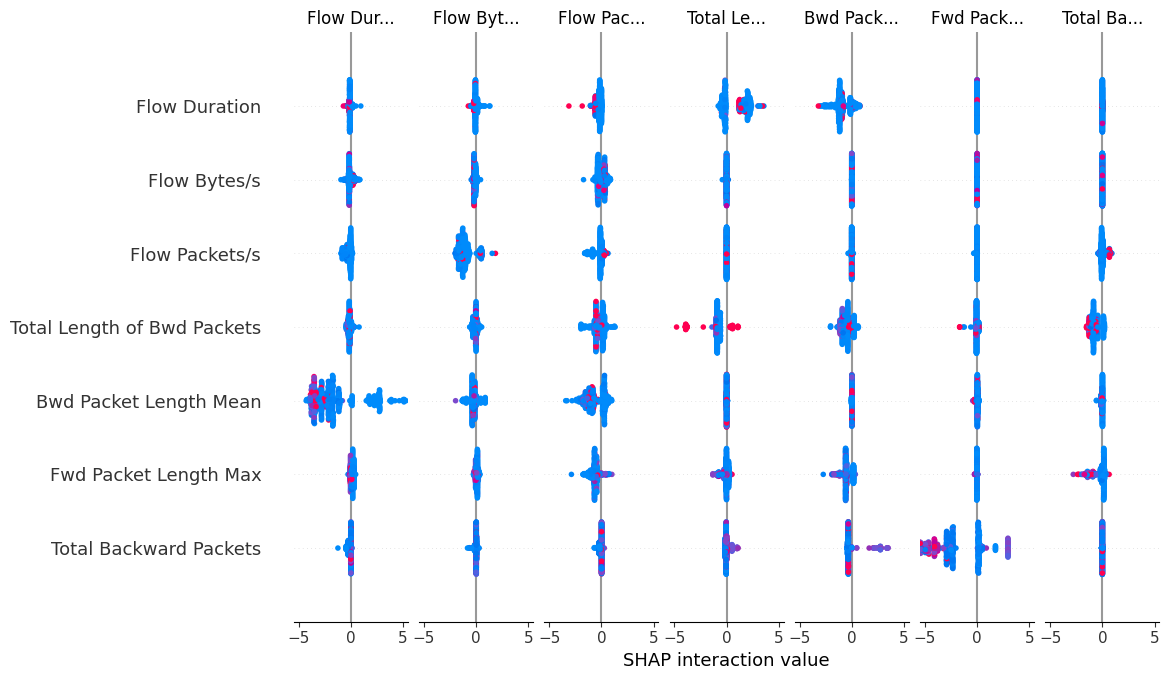

In [41]:
shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=X_sample.columns
)

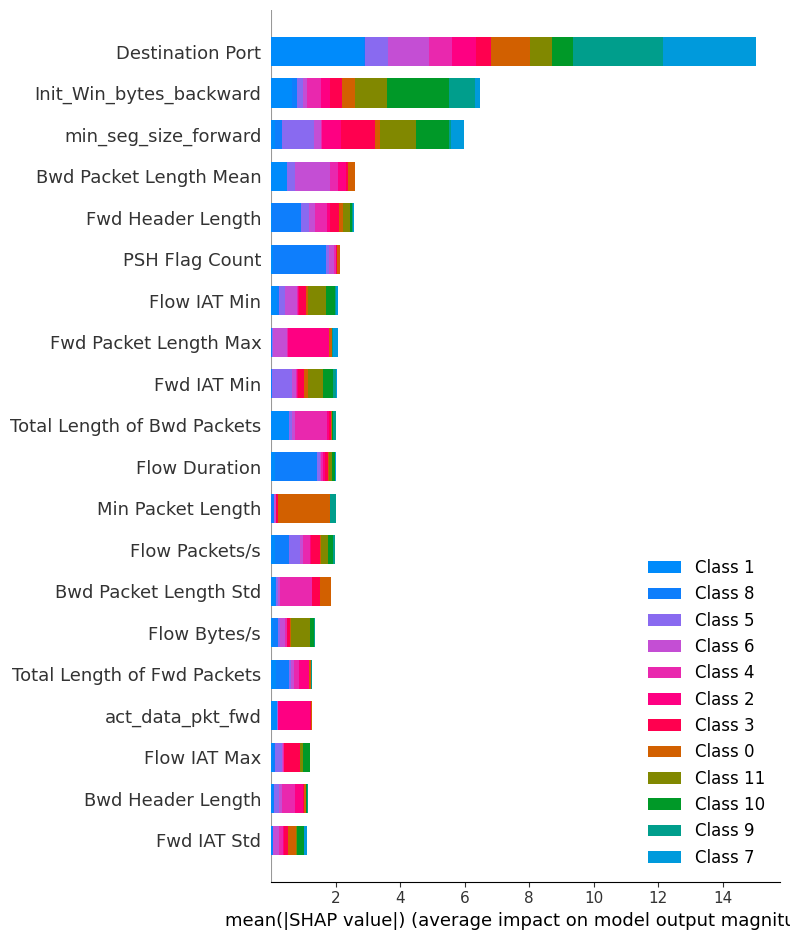

In [42]:
shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=X_sample.columns,
    plot_type="bar"
)

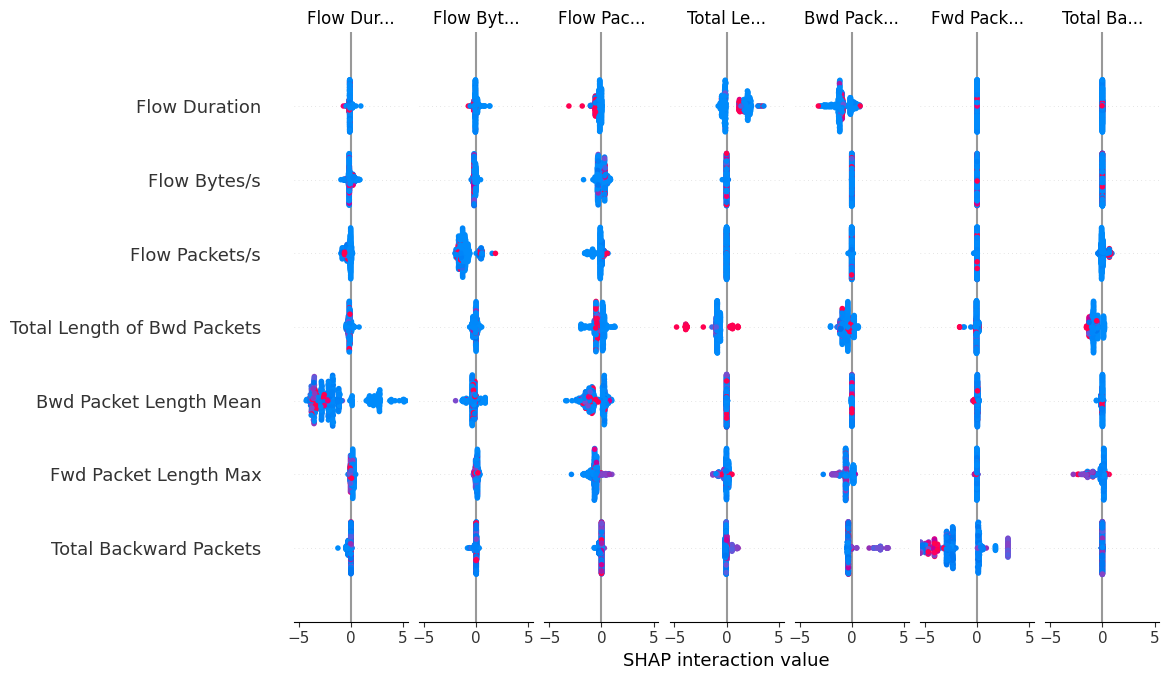

In [43]:
shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=X_sample.columns
)

In [44]:
plt.savefig(
    "/kaggle/working/shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [45]:
# Derive thresholds from benign training data only

benign_train = train_df[train_df["Binary_Label"] == 0]

candidate_features = ["Flow Packets/s", "Flow Bytes/s"]

available_features = [
    col for col in candidate_features
    if col in benign_train.columns
]

rule_thresholds = {}

for col in available_features:
    values = pd.to_numeric(
        benign_train[col], errors="coerce"
    )

    values = values.replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    if len(values) > 0:
        rule_thresholds[col] = float(
            values.quantile(0.99)
        )

print("Available features:", available_features)
print("Rule thresholds:", rule_thresholds)

Available features: ['Flow Packets/s', 'Flow Bytes/s']
Rule thresholds: {'Flow Packets/s': 4.700622091913581, 'Flow Bytes/s': 0.4157146319155987}


In [46]:
def evaluate_rules(flow):
    triggered = []

    # Rule 1: Unusually high traffic rate
    for feature, threshold in rule_thresholds.items():
        value = pd.to_numeric(
            pd.Series([flow.get(feature, np.nan)]),
            errors="coerce"
        ).iloc[0]

        if pd.notna(value) and value > threshold:
            triggered.append(
                feature + " above benign 99th percentile"
            )

    # Rule 2: Strong forward/backward packet imbalance
    fwd = flow.get("Total Fwd Packets", 0)
    bwd = flow.get("Total Backward Packets", 0)

    fwd = max(float(fwd or 0), 0)
    bwd = max(float(bwd or 0), 0)

    ratio = (fwd + 1) / (bwd + 1)

    if ratio >= 20 or ratio <= 1 / 20:
        triggered.append(
            "Strong forward/backward packet imbalance"
        )

    return triggered

In [47]:
example_flow = X_test.iloc[0].to_dict()

print("Triggered rules:")
print(evaluate_rules(example_flow))

Triggered rules:
[]


In [48]:

# Check the rate features in the test data

for col in ["Flow Packets/s", "Flow Bytes/s"]:
    values = pd.to_numeric(X_test[col], errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan).dropna()

    print("\nFeature:", col)
    print(values.describe(percentiles=[0.50, 0.90, 0.95, 0.99]))
    print("Values above our threshold:",
          (values > rule_thresholds[col]).sum())
    print("Percentage flagged:",
          round((values > rule_thresholds[col]).mean() * 100, 2), "%")



Feature: Flow Packets/s
count    504146.000000
mean          0.000798
std           0.998846
min         -10.100754
50%          -0.232817
90%          -0.008907
95%           0.525875
99%           3.467174
max          19.501998
Name: Flow Packets/s, dtype: float64
Values above our threshold: 3388
Percentage flagged: 0.67 %

Feature: Flow Bytes/s
count    504146.000000
mean          0.002526
std           1.049331
min          -0.509286
50%          -0.052980
90%          -0.004909
95%           0.023313
99%           0.415715
max          78.673293
Name: Flow Bytes/s, dtype: float64
Values above our threshold: 3900
Percentage flagged: 0.77 %


In [49]:

# Compare each rate rule with the actual test labels

y_true_binary = test_df["Binary_Label"].astype(int)

for col in ["Flow Packets/s", "Flow Bytes/s"]:
    values = pd.to_numeric(X_test[col], errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan)

    rule_alert = (values > rule_thresholds[col]).fillna(False).astype(int)

    tp = ((rule_alert == 1) & (y_true_binary == 1)).sum()
    fp = ((rule_alert == 1) & (y_true_binary == 0)).sum()
    fn = ((rule_alert == 0) & (y_true_binary == 1)).sum()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    print("\nRule:", col)
    print("True positives:", tp)
    print("False positives:", fp)
    print("False negatives:", fn)
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))



Rule: Flow Packets/s
True positives: 95
False positives: 3293
False negatives: 85039
Precision: 0.028
Recall: 0.0011

Rule: Flow Bytes/s
True positives: 12
False positives: 3888
False negatives: 85122
Precision: 0.0031
Recall: 0.0001


In [50]:

# Check whether the features are in their original scale
check_features = [
    "Flow Packets/s",
    "Flow Bytes/s",
    "Total Fwd Packets",
    "Total Backward Packets"
]

for col in check_features:
    print("\n", col)
    print("Training data:")
    print(train_df[col].describe()[["min", "50%", "max"]])
    print("Test features:")
    print(X_test[col].describe()[["min", "50%", "max"]])



 Flow Packets/s
Training data:
min   -10.100754
50%    -0.232828
max    19.501998
Name: Flow Packets/s, dtype: float64
Test features:
min   -10.100754
50%    -0.232817
max    19.501998
Name: Flow Packets/s, dtype: float64

 Flow Bytes/s
Training data:
min    -9.974702
50%    -0.052980
max    78.673293
Name: Flow Bytes/s, dtype: float64
Test features:
min    -0.509286
50%    -0.052980
max    78.673293
Name: Flow Bytes/s, dtype: float64

 Total Fwd Packets
Training data:
min     -0.011625
50%     -0.010411
max    266.801509
Name: Total Fwd Packets, dtype: float64
Test features:
min     -0.011625
50%     -0.010411
max    265.464760
Name: Total Fwd Packets, dtype: float64

 Total Backward Packets
Training data:
min     -0.010902
50%     -0.009080
max    265.898811
Name: Total Backward Packets, dtype: float64
Test features:
min     -0.010902
50%     -0.009080
max    265.295800
Name: Total Backward Packets, dtype: float64


In [51]:
print("Scaler:", type(scaler).__name__)
print("Scaler feature count:", scaler.n_features_in_)
print("X_test feature count:", X_test.shape[1])

print("\nFirst 5 scaler features:")
print(list(scaler.feature_names_in_[:5]))

print("\nFirst 5 X_test columns:")
print(list(X_test.columns[:5]))

print("\nColumn order matches:",
      list(scaler.feature_names_in_) == list(X_test.columns))

Scaler: StandardScaler
Scaler feature count: 70
X_test feature count: 70

First 5 scaler features:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets']

First 5 X_test columns:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets']

Column order matches: True


In [53]:

# Convert scaled training and test features back to original values

X_train_original = pd.DataFrame(
    scaler.inverse_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_original = pd.DataFrame(
    scaler.inverse_transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Original-scale training features:")
print(X_train_original[
    ["Flow Packets/s", "Flow Bytes/s",
     "Total Fwd Packets", "Total Backward Packets"]
].describe())

print("\nOriginal-scale test features:")
print(X_test_original[
    ["Flow Packets/s", "Flow Bytes/s",
     "Total Fwd Packets", "Total Backward Packets"]
].describe())


Original-scale training features:
       Flow Packets/s  Flow Bytes/s  Total Fwd Packets  Total Backward Packets
count    2.016584e+06  2.016584e+06       2.016584e+06            2.016584e+06
mean     4.726087e+04  1.397460e+06       1.055506e+01            1.195131e+01
std      2.026865e+05  2.630665e+07       8.236159e+02            1.097819e+03
min     -2.000000e+06 -2.610000e+08       1.000000e+00            4.973799e-14
25%      2.015763e+00  1.194263e+02       2.000000e+00            1.000000e+00
50%      6.940192e+01  3.714202e+03       2.000000e+00            2.000000e+00
75%      1.785714e+04  1.066667e+05       6.000000e+00            5.000000e+00
max      4.000000e+06  2.071000e+09       2.197590e+05            2.919220e+05

Original-scale test features:
       Flow Packets/s  Flow Bytes/s  Total Fwd Packets  Total Backward Packets
count    5.041460e+05  5.041460e+05      504146.000000            5.041460e+05
mean     4.742157e+04  1.463883e+06           9.074066            

In [54]:
print("X_train_original:", X_train_original.shape)
print("X_test_original:", X_test_original.shape)

print("train_df:", train_df.shape)
print("test_df:", test_df.shape)

print("\nTraining labels:")
print(train_df["Binary_Label"].value_counts())

print("\nTest labels:")
print(test_df["Binary_Label"].value_counts())

print("\nNegative rate values:")
for col in ["Flow Packets/s", "Flow Bytes/s"]:
    print(col)
    print("Training:", (X_train_original[col] < 0).sum())
    print("Testing:", (X_test_original[col] < 0).sum())

X_train_original: (2016584, 70)
X_test_original: (504146, 70)
train_df: (2016638, 72)
test_df: (504160, 72)

Training labels:
Binary_Label
0    1676045
1     340593
Name: count, dtype: int64

Test labels:
Binary_Label
0    419012
1     85148
Name: count, dtype: int64

Negative rate values:
Flow Packets/s
Training: 96
Testing: 11
Flow Bytes/s
Training: 70
Testing: 8


In [55]:
print("Possible label variables:")

for name in ["y_train", "y_test", "y_train_binary", "y_test_binary",
             "y_train_bin", "y_test_bin"]:
    if name in globals():
        value = globals()[name]
        print(name, "shape:", getattr(value, "shape", None))

Possible label variables:
y_train shape: (2016584,)
y_test shape: (504146,)


In [56]:
print("X_train index:", X_train.index[:5].tolist())
print("X_test index:", X_test.index[:5].tolist())

print("train_df index:", train_df.index[:5].tolist())
print("test_df index:", test_df.index[:5].tolist())

X_train index: [0, 1, 2, 3, 4]
X_test index: [0, 1, 2, 3, 4]
train_df index: [0, 1, 2, 3, 4]
test_df index: [0, 1, 2, 3, 4]


In [57]:
import numpy as np
import pandas as pd

# Select benign training rows only
benign_train_original = X_train_original.loc[
    np.asarray(y_train) == 0
]

# Features used for behavioural rules
candidate_features = [
    "Flow Packets/s",
    "Flow Bytes/s"
]

rule_thresholds = {}

for col in candidate_features:
    # Convert values to numeric
    values = pd.to_numeric(
        benign_train_original[col],
        errors="coerce"
    )

    # Remove invalid infinite and negative rate values
    values = values.replace([np.inf, -np.inf], np.nan)
    values = values[values >= 0].dropna()

    if len(values) > 0:
        rule_thresholds[col] = float(values.quantile(0.99))

print("Number of benign training flows:", len(benign_train_original))
print("Rule thresholds:", rule_thresholds)

Number of benign training flows: 1676045
Rule thresholds: {'Flow Packets/s': 999999.9999999998, 'Flow Bytes/s': 12333333.333333299}


In [58]:
for col in ["Flow Packets/s", "Flow Bytes/s"]:
    values = pd.to_numeric(
        benign_train_original[col],
        errors="coerce"
    ).replace([np.inf, -np.inf], np.nan).dropna()

    values = values[values >= 0]

    print("\nFeature:", col)
    print("Minimum:", values.min())
    print("50th percentile:", values.quantile(0.50))
    print("90th percentile:", values.quantile(0.90))
    print("95th percentile:", values.quantile(0.95))
    print("99th percentile:", values.quantile(0.99))
    print("99.5th percentile:", values.quantile(0.995))
    print("99.9th percentile:", values.quantile(0.999))
    print("Maximum:", values.max())
    print("Unique values:", values.nunique())


Feature: Flow Packets/s
Minimum: 0.016701328997442033
50th percentile: 84.96898632000375
90th percentile: 46511.62791000001
95th percentile: 500000.0000000001
99th percentile: 999999.9999999998
99.5th percentile: 2000000.0
99.9th percentile: 2000000.0
Maximum: 3999999.999999999
Unique values: 770160

Feature: Flow Bytes/s
Minimum: 1.6298145055770874e-09
50th percentile: 4247.6719490005635
90th percentile: 1424999.9999999995
95th percentile: 2319999.9999999986
99th percentile: 12333333.333333299
99.5th percentile: 31000000.0
99.9th percentile: 309000000.0
Maximum: 2071000000.0
Unique values: 1046040


In [59]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

y_true = np.asarray(y_test).astype(int)

for col, threshold in rule_thresholds.items():

    values = pd.to_numeric(
        X_test_original[col],
        errors="coerce"
    ).to_numpy()

    # Invalid rates should not trigger the rule
    flagged = np.isfinite(values) & (values >= 0) & (values > threshold)

    # 1 = rule flags the flow as suspicious
    y_rule = flagged.astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_rule, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )
    fpr = fp / (fp + tn) if fp + tn else 0

    print("\nRule:", col)
    print("Threshold:", threshold)
    print("Flows flagged:", int(flagged.sum()))
    print("TP:", tp, "FP:", fp)
    print("FN:", fn, "TN:", tn)
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-score:", round(f1, 4))
    print("False positive rate:", round(fpr, 4))


Rule: Flow Packets/s
Threshold: 999999.9999999998
Flows flagged: 3388
TP: 0 FP: 3293
FN: 384 TN: 415719
Precision: 0.0
Recall: 0.0
F1-score: 0
False positive rate: 0.0079

Rule: Flow Bytes/s
Threshold: 12333333.333333299
Flows flagged: 3900
TP: 0 FP: 3888
FN: 384 TN: 415124
Precision: 0.0
Recall: 0.0
F1-score: 0
False positive rate: 0.0093


In [60]:
print("y_train distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\ny_test distribution:")
print(pd.Series(y_test).value_counts().sort_index())

print("\ntest_df label distribution:")
print(test_df["Binary_Label"].value_counts().sort_index())

print("\nFirst 20 y_test labels:")
print(np.asarray(y_test)[:20])

print("\nFirst 20 test_df labels:")
print(test_df["Binary_Label"].iloc[:20].to_list())

y_train distribution:
0     1676045
1        1564
2      102382
3        8318
4      138165
5        4242
6        4284
7        4802
8       72508
9        2584
10       1157
11        533
Name: count, dtype: int64

y_test distribution:
0     419012
1        384
2      25632
3       1968
4      34681
5        986
6       1101
7       1129
8      18186
9        635
10       313
11       119
Name: count, dtype: int64

test_df label distribution:
Binary_Label
0    419012
1     85148
Name: count, dtype: int64

First 20 y_test labels:
[0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0]

First 20 test_df labels:
[0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0]


In [61]:
import numpy as np

# Convert multiclass labels to binary labels
y_train_binary = (np.asarray(y_train) != 0).astype(int)
y_test_binary = (np.asarray(y_test) != 0).astype(int)

print("Binary training labels:")
print("Benign:", np.sum(y_train_binary == 0))
print("Attack:", np.sum(y_train_binary == 1))

print("\nBinary test labels:")
print("Benign:", np.sum(y_test_binary == 0))
print("Attack:", np.sum(y_test_binary == 1))

Binary training labels:
Benign: 1676045
Attack: 340539

Binary test labels:
Benign: 419012
Attack: 85134


In [62]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Use binary labels: 0 = benign, 1 = attack
y_true = (np.asarray(y_test) != 0).astype(int)

for col, threshold in rule_thresholds.items():

    values = pd.to_numeric(
        X_test_original[col],
        errors="coerce"
    ).to_numpy()

    # Flag flows exceeding the threshold
    flagged = (
        np.isfinite(values) &
        (values >= 0) &
        (values > threshold)
    )

    y_rule = flagged.astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_rule, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    fpr = fp / (fp + tn) if fp + tn else 0

    print("\nRule:", col)
    print("Threshold:", threshold)
    print("Flows flagged:", int(flagged.sum()))
    print("TP:", tp, "FP:", fp)
    print("FN:", fn, "TN:", tn)
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-score:", round(f1, 4))
    print("False positive rate:", round(fpr, 4))


Rule: Flow Packets/s
Threshold: 999999.9999999998
Flows flagged: 3388
TP: 95 FP: 3293
FN: 85039 TN: 415719
Precision: 0.028
Recall: 0.0011
F1-score: 0.0021
False positive rate: 0.0079

Rule: Flow Bytes/s
Threshold: 12333333.333333299
Flows flagged: 3900
TP: 12 FP: 3888
FN: 85122 TN: 415124
Precision: 0.0031
Recall: 0.0001
F1-score: 0.0003
False positive rate: 0.0093


In [63]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Correct binary test labels
y_true = (np.asarray(y_test) != 0).astype(int)

# Original packet counts
fwd = X_test_original["Total Fwd Packets"].to_numpy()
bwd = X_test_original["Total Backward Packets"].to_numpy()

# Avoid division by zero
ratio = (fwd + 1) / (bwd + 1)

# Flag strong imbalance in either direction
flagged = (
    np.isfinite(fwd) &
    np.isfinite(bwd) &
    (fwd >= 0) &
    (bwd >= 0) &
    ((ratio >= 20) | (ratio <= 1 / 20))
)

y_rule = flagged.astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_true, y_rule, labels=[0, 1]
).ravel()

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)
fpr = fp / (fp + tn) if fp + tn else 0

print("Flows flagged:", int(flagged.sum()))
print("TP:", tp, "FP:", fp)
print("FN:", fn, "TN:", tn)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
print("False positive rate:", round(fpr, 4))

Flows flagged: 584
TP: 0 FP: 584
FN: 85134 TN: 418428
Precision: 0.0
Recall: 0.0
F1-score: 0
False positive rate: 0.0014


In [64]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Predict using the scaled test features
y_pred = binary_xgb.predict(X_test)

# Correct binary ground-truth labels
y_true = (np.asarray(y_test) != 0).astype(int)

# Evaluation
tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=[0, 1]
).ravel()

print("Binary XGBoost Results")
print("----------------------")
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("TP:", tp)
print("FP:", fp)
print("FN:", fn)
print("TN:", tn)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Attack"],
    zero_division=0
))

NameError: name 'binary_xgb' is not defined

In [65]:
for name, obj in globals().copy().items():
    if hasattr(obj, "predict") and hasattr(obj, "predict_proba"):
        print(name, "->", type(obj).__name__)

LogisticRegression -> type
RandomForestClassifier -> ABCMeta
XGBClassifier -> type
log_reg_model -> LogisticRegression
random_forest_model -> RandomForestClassifier
xgboost_model -> XGBClassifier
multiclass_model -> XGBClassifier
model -> XGBClassifier
model_selected -> XGBClassifier


In [66]:
for name in ["xgboost_model", "model", "model_selected", "multiclass_model"]:
    obj = globals().get(name)

    if obj is not None:
        print("\nModel:", name)
        print("Classes:", getattr(obj, "classes_", "Not available"))
        print("Number of classes:",
              len(obj.classes_) if hasattr(obj, "classes_") else "Unknown")


Model: xgboost_model
Classes: [0 1]
Number of classes: 2

Model: model
Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11]
Number of classes: 12

Model: model_selected
Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11]
Number of classes: 12

Model: multiclass_model
Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11]
Number of classes: 12


In [67]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Predict using the binary XGBoost model
y_pred = xgboost_model.predict(X_test)

# Convert multiclass labels into binary labels
# 0 = Benign, any non-zero class = Attack
y_true = (np.asarray(y_test) != 0).astype(int)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=[0, 1]
).ravel()

print("Binary XGBoost Results")
print("----------------------")
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("TP:", tp)
print("FP:", fp)
print("FN:", fn)
print("TN:", tn)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Attack"],
    zero_division=0
))

Binary XGBoost Results
----------------------
Accuracy: 0.9992
TP: 85013
FP: 289
FN: 121
TN: 418723

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00    419012
      Attack       1.00      1.00      1.00     85134

    accuracy                           1.00    504146
   macro avg       1.00      1.00      1.00    504146
weighted avg       1.00      1.00      1.00    504146



In [68]:
import numpy as np
import pandas as pd

# Binary ground-truth labels
y_true = (np.asarray(y_test) != 0).astype(int)

# XGBoost predictions
y_pred = np.asarray(xgboost_model.predict(X_test)).astype(int)

# Find attacks missed by XGBoost
missed_mask = (y_true == 1) & (y_pred == 0)

print("Total missed attacks:", int(missed_mask.sum()))

# Inspect selected features for missed attacks
features_to_inspect = [
    "Flow Packets/s",
    "Flow Bytes/s",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Duration"
]

available_features = [
    col for col in features_to_inspect
    if col in X_test_original.columns
]

missed_attacks = X_test_original.loc[
    missed_mask, available_features
]

print("\nMissed attack feature summary:")
print(missed_attacks.describe().T)

Total missed attacks: 121

Missed attack feature summary:
                        count          mean           std           min  \
Flow Packets/s          121.0  1.126977e+04  6.646821e+04  4.400067e-01   
Flow Bytes/s            121.0  5.551270e+04  3.909073e+05  1.629815e-09   
Total Fwd Packets       121.0  3.553719e+00  7.350681e+00  1.000000e+00   
Total Backward Packets  121.0  3.008264e+00  3.837308e+00  4.973799e-14   
Flow Duration           121.0  1.330158e+06  2.236161e+06  3.000000e+00   

                                  25%           50%           75%  \
Flow Packets/s               5.870273  5.981893e+00  6.018634e+00   
Flow Bytes/s                17.560085  1.793166e+01  1.805271e+01   
Total Fwd Packets            3.000000  3.000000e+00  3.000000e+00   
Total Backward Packets       3.000000  3.000000e+00  3.000000e+00   
Flow Duration           996999.000000  1.003027e+06  1.024441e+06   

                                 max  
Flow Packets/s          6.666667e+05 

In [69]:
# Separate the test flows into three groups
correct_attacks = (y_true == 1) & (y_pred == 1)
missed_attacks = (y_true == 1) & (y_pred == 0)
benign_flows = (y_true == 0)

features_to_inspect = [
    "Flow Packets/s",
    "Flow Bytes/s",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Duration"
]

for group_name, mask in [
    ("Missed attacks", missed_attacks),
    ("Detected attacks", correct_attacks),
    ("Benign flows", benign_flows)
]:
    print("\n", group_name)
    print(
        X_test_original.loc[mask, features_to_inspect]
        .median()
        .round(3)
    )


 Missed attacks
Flow Packets/s                  5.982
Flow Bytes/s                   17.932
Total Fwd Packets               3.000
Total Backward Packets          3.000
Flow Duration             1003027.000
dtype: float64

 Detected attacks
Flow Packets/s                  1.104
Flow Bytes/s                  143.296
Total Fwd Packets               4.000
Total Backward Packets          5.000
Flow Duration             6030816.000
dtype: float64

 Benign flows
Flow Packets/s               85.212
Flow Bytes/s               4261.138
Total Fwd Packets             2.000
Total Backward Packets        2.000
Flow Duration             38327.500
dtype: float64


In [70]:
import numpy as np
from sklearn.metrics import confusion_matrix

y_true = (np.asarray(y_test) != 0).astype(int)
y_pred = np.asarray(xgboost_model.predict(X_test)).astype(int)

byte_rate = X_test_original["Flow Bytes/s"].to_numpy()
duration = X_test_original["Flow Duration"].to_numpy()

# Candidate rule: low byte rate + duration near 1,000,000
rule_flagged = (
    np.isfinite(byte_rate) &
    np.isfinite(duration) &
    (byte_rate >= 0) &
    (byte_rate <= 20) &
    (duration >= 900_000) &
    (duration <= 1_100_000)
)

# Evaluate the rule by itself
tn, fp, fn, tp = confusion_matrix(
    y_true, rule_flagged.astype(int), labels=[0, 1]
).ravel()

print("RULE-ONLY RESULTS")
print("Flows flagged:", int(rule_flagged.sum()))
print("TP:", tp, "FP:", fp)
print("FN:", fn, "TN:", tn)

# Check whether it catches attacks missed by XGBoost
missed_by_model = (y_true == 1) & (y_pred == 0)
caught_missed = missed_by_model & rule_flagged

print("\nHYBRID POTENTIAL")
print("Attacks missed by XGBoost:", int(missed_by_model.sum()))
print("Missed attacks caught by rule:", int(caught_missed.sum()))
print("Additional benign flows flagged:",
      int(((y_true == 0) & rule_flagged).sum()))

RULE-ONLY RESULTS
Flows flagged: 802
TP: 101 FP: 701
FN: 85033 TN: 418311

HYBRID POTENTIAL
Attacks missed by XGBoost: 121
Missed attacks caught by rule: 95
Additional benign flows flagged: 701


In [71]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_true = (np.asarray(y_test) != 0).astype(int)
y_pred = np.asarray(xgboost_model.predict(X_test)).astype(int)

byte_rate = X_test_original["Flow Bytes/s"].to_numpy()
duration = X_test_original["Flow Duration"].to_numpy()

rule_flagged = (
    np.isfinite(byte_rate) &
    np.isfinite(duration) &
    (byte_rate >= 0) &
    (byte_rate <= 20) &
    (duration >= 900_000) &
    (duration <= 1_100_000)
).astype(int)

# Hybrid: flag as attack if either method flags it
hybrid_pred = ((y_pred == 1) | (rule_flagged == 1)).astype(int)

for name, predictions in [
    ("XGBoost", y_pred),
    ("Hybrid", hybrid_pred)
]:
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print("\n", name)
    print("TP:", tp, "FP:", fp, "FN:", fn, "TN:", tn)
    print("Precision:", round(precision, 5))
    print("Recall:", round(recall, 5))
    print("F1-score:", round(f1, 5))


 XGBoost
TP: 85013 FP: 289 FN: 121 TN: 418723
Precision: 0.99661
Recall: 0.99858
F1-score: 0.99759

 Hybrid
TP: 85108 FP: 986 FN: 26 TN: 418026
Precision: 0.98855
Recall: 0.99969
F1-score: 0.99409


In [72]:
import numpy as np
from sklearn.model_selection import train_test_split

# Original-scale training features
X_rule_train = X_train_original.copy()

# Binary labels: 0 = benign, 1 = attack
y_rule_train = (np.asarray(y_train) != 0).astype(int)

# Split into rule-training and validation sets
X_rule_fit, X_rule_val, y_rule_fit, y_rule_val = train_test_split(
    X_rule_train,
    y_rule_train,
    test_size=0.20,
    random_state=42,
    stratify=y_rule_train
)

print("Rule-training rows:", len(X_rule_fit))
print("Validation rows:", len(X_rule_val))

print("\nRule-training labels:")
print("Benign:", np.sum(y_rule_fit == 0))
print("Attack:", np.sum(y_rule_fit == 1))

print("\nValidation labels:")
print("Benign:", np.sum(y_rule_val == 0))
print("Attack:", np.sum(y_rule_val == 1))

Rule-training rows: 1613267
Validation rows: 403317

Rule-training labels:
Benign: 1340836
Attack: 272431

Validation labels:
Benign: 335209
Attack: 68108


In [73]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone

# Binary labels
y_binary = (np.asarray(y_train) != 0).astype(int)

# Split scaled and original-scale features together
X_fit_scaled, X_val_scaled, X_fit_original, X_val_original, y_fit, y_val = train_test_split(
    X_train,
    X_train_original,
    y_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

# Create a separate model with the same settings
validation_model = clone(xgboost_model)

# Train only on the 80% training subset
validation_model.fit(X_fit_scaled, y_fit)

# Predict on the unseen validation subset
val_predictions = validation_model.predict(X_val_scaled)

print("Validation model trained successfully!")
print("Validation rows:", len(y_val))
print("Validation predictions:", len(val_predictions))

Validation model trained successfully!
Validation rows: 403317
Validation predictions: 403317


In [74]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Actual validation labels and predicted labels
y_true = y_val
y_pred = val_predictions

# Calculate metrics
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, zero_division=0))
print("Recall:", recall_score(y_true, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_true, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Benign", "Attack"],
    zero_division=0
))

Accuracy: 0.9991768261689936
Precision: 0.9968186482920393
Recall: 0.9983115052563576
F1 Score: 0.9975645182587772

Confusion Matrix:
[[334992    217]
 [   115  67993]]

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00    335209
      Attack       1.00      1.00      1.00     68108

    accuracy                           1.00    403317
   macro avg       1.00      1.00      1.00    403317
weighted avg       1.00      1.00      1.00    403317



In [75]:
import pandas as pd
import numpy as np

# Identify missed and detected attacks
missed_mask = (y_val == 1) & (val_predictions == 0)
detected_mask = (y_val == 1) & (val_predictions == 1)
benign_mask = (y_val == 0)

# Compare network-flow features
features_to_check = [
    "Flow Packets/s",
    "Flow Bytes/s",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Duration"
]

comparison = pd.DataFrame({
    "Missed attacks": X_val_original.loc[
        X_val_original.index[missed_mask], features_to_check
    ].median(),
    "Detected attacks": X_val_original.loc[
        X_val_original.index[detected_mask], features_to_check
    ].median(),
    "Benign flows": X_val_original.loc[
        X_val_original.index[benign_mask], features_to_check
    ].median()
})

print("Number of missed attacks:", missed_mask.sum())
print("Number of detected attacks:", detected_mask.sum())

print("\nMedian feature values:")
print(comparison)

Number of missed attacks: 115
Number of detected attacks: 67993

Median feature values:
                        Missed attacks  Detected attacks  Benign flows
Flow Packets/s                6.001692      1.087062e+00     84.774500
Flow Bytes/s                 17.739600      1.432442e+02   4211.357505
Total Fwd Packets             3.000000      4.000000e+00      2.000000
Total Backward Packets        3.000000      5.000000e+00      2.000000
Flow Duration            997255.000000      6.062809e+06  41645.000000


In [76]:
# Candidate pattern: low byte rate and long duration
byte_rate = X_rule_fit["Flow Bytes/s"]
duration = X_rule_fit["Flow Duration"]

valid = (
    np.isfinite(byte_rate) &
    np.isfinite(duration) &
    (byte_rate >= 0) &
    (duration >= 0)
)

# Use fixed, interpretable ranges for initial exploration
low_bytes = byte_rate <= 20
long_duration = duration.between(900_000, 1_100_000)

candidate_rule = valid & low_bytes & long_duration

for label, name in [(0, "Benign"), (1, "Attack")]:
    group = y_rule_fit == label
    total = group.sum()
    matched = (group & candidate_rule).sum()

    print(f"{name} flows matching rule: {matched:,} / {total:,}")
    print(f"{name} match rate: {matched / total:.4%}\n")

Benign flows matching rule: 2,406 / 1,340,836
Benign match rate: 0.1794%

Attack flows matching rule: 316 / 272,431
Attack match rate: 0.1160%



In [77]:
# Candidate rule on validation data
byte_rate = X_val_original["Flow Bytes/s"]
duration = X_val_original["Flow Duration"]

valid = (
    np.isfinite(byte_rate) &
    np.isfinite(duration) &
    (byte_rate >= 0) &
    (duration >= 0)
)

rule_predictions = (
    valid &
    (byte_rate <= 20) &
    duration.between(900_000, 1_100_000)
).astype(int)

# Actual attacks missed by XGBoost
missed_mask = (y_val == 1) & (val_predictions == 0)

# Additional attacks caught by the rule
additional_attacks = missed_mask & (rule_predictions == 1)

print("Attacks missed by XGBoost:", missed_mask.sum())
print("Missed attacks caught by rule:", additional_attacks.sum())
print("Missed attacks still not caught:",
      missed_mask.sum() - additional_attacks.sum())

print("\nTotal validation flows flagged by rule:",
      rule_predictions.sum())

print("Benign flows flagged by rule:",
      ((y_val == 0) & (rule_predictions == 1)).sum())

Attacks missed by XGBoost: 115
Missed attacks caught by rule: 75
Missed attacks still not caught: 40

Total validation flows flagged by rule: 653
Benign flows flagged by rule: 570


In [78]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Hybrid: classify as attack if either method flags it
hybrid_predictions = (
    (val_predictions == 1) |
    (rule_predictions == 1)
).astype(int)

def evaluate(name, actual, predicted):
    print(f"\n{name}")
    print("Accuracy:", accuracy_score(actual, predicted))
    print("Precision:", precision_score(actual, predicted, zero_division=0))
    print("Recall:", recall_score(actual, predicted, zero_division=0))
    print("F1 Score:", f1_score(actual, predicted, zero_division=0))
    print("Confusion Matrix:\n", confusion_matrix(actual, predicted))

evaluate("XGBoost Only", y_val, val_predictions)
evaluate("Hybrid System", y_val, hybrid_predictions)


XGBoost Only
Accuracy: 0.9991768261689936
Precision: 0.9968186482920393
Recall: 0.9983115052563576
F1 Score: 0.9975645182587772
Confusion Matrix:
 [[334992    217]
 [   115  67993]]

Hybrid System
Accuracy: 0.9979792570112344
Precision: 0.9887425010531209
Recall: 0.9994126974804722
F1 Score: 0.994048966418646
Confusion Matrix:
 [[334434    775]
 [    40  68068]]


In [79]:

# Get the probability of an attack from the XGBoost model

val_probabilities = validation_model.predict_proba(X_val_scaled)[:, 1]

print("First 10 attack probabilities:")
print(val_probabilities[:10])

print("\nMinimum probability:", val_probabilities.min())
print("Maximum probability:", val_probabilities.max())
print("Mean probability:", val_probabilities.mean())


First 10 attack probabilities:
[3.4746998e-07 1.2580212e-07 2.6619728e-04 4.6268191e-08 1.7829018e-06
 3.6083333e-07 6.9927529e-07 8.9750101e-06 1.1410627e-07 6.3946743e-07]

Minimum probability: 9.575314e-10
Maximum probability: 0.9999999
Mean probability: 0.16881344


In [80]:
from sklearn.base import clone

validation_model = clone(xgboost_model)

validation_model.fit(X_fit_scaled, y_fit)

print("Validation model trained successfully!")

Validation model trained successfully!


In [81]:
print("xgboost_model exists:", 'xgboost_model' in globals())
print("X_train exists:", 'X_train' in globals())
print("scaler exists:", 'scaler' in globals())
print("validation_model exists:", 'validation_model' in globals())

xgboost_model exists: True
X_train exists: True
scaler exists: True
validation_model exists: True


In [82]:
import numpy as np

print("Probability distribution:")

print("Low probability (below 0.30):",
      np.sum(val_probabilities < 0.30))

print("Moderate probability (0.30 to below 0.70):",
      np.sum((val_probabilities >= 0.30) &
             (val_probabilities < 0.70)))

print("High probability (0.70 and above):",
      np.sum(val_probabilities >= 0.70))

print("Total validation flows:", len(val_probabilities))

Probability distribution:
Low probability (below 0.30): 334916
Moderate probability (0.30 to below 0.70): 277
High probability (0.70 and above): 68124
Total validation flows: 403317


In [83]:
print("X_val_original exists:", 'X_val_original' in globals())
print("y_val exists:", 'y_val' in globals())
print("val_predictions exists:", 'val_predictions' in globals())

if 'X_val_original' in globals():
    print("\nValidation data shape:", X_val_original.shape)
    print("Available columns:")
    print(X_val_original.columns.tolist())

X_val_original exists: True
y_val exists: True
val_predictions exists: True

Validation data shape: (403317, 70)
Available columns:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Fl

In [84]:
import numpy as np

# Get the two original features
byte_rate = X_val_original["Flow Bytes/s"].to_numpy()
duration = X_val_original["Flow Duration"].to_numpy()

# Check for valid values
valid_values = (
    np.isfinite(byte_rate) &
    np.isfinite(duration) &
    (byte_rate >= 0) &
    (duration >= 0)
)

# Apply the candidate rule
rule_flags = (
    valid_values &
    (byte_rate <= 20) &
    (duration >= 900000) &
    (duration <= 1100000)
)

# Compare the rule with the actual validation labels
actual_labels = np.asarray(y_val)
rule_predictions = rule_flags.astype(int)

tp = np.sum((actual_labels == 1) & (rule_predictions == 1))
fp = np.sum((actual_labels == 0) & (rule_predictions == 1))
fn = np.sum((actual_labels == 1) & (rule_predictions == 0))
tn = np.sum((actual_labels == 0) & (rule_predictions == 0))

print("Rule Evaluation")
print("----------------")
print("Total flows flagged:", np.sum(rule_flags))
print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Negatives:", tn)

precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

print("\nPrecision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

Rule Evaluation
----------------
Total flows flagged: 653
True Positives: 83
False Positives: 570
False Negatives: 68025
True Negatives: 334639

Precision: 0.1271
Recall: 0.0012
F1-score: 0.0024


In [85]:
# Check the number of flows flagged by the candidate rule
# and the model's predictions for those same flows.

print("Rule-flagged flows:", int(rule_flags.sum()))

print("\nAmong rule-flagged flows:")
print(
    "XGBoost predicted attack:",
    int(np.sum(rule_flags & (val_predictions == 1)))
)

print(
    "XGBoost predicted benign:",
    int(np.sum(rule_flags & (val_predictions == 0)))
)

print("\nAmong flows NOT flagged by the rule:")
print(
    "XGBoost predicted attack:",
    int(np.sum((~rule_flags) & (val_predictions == 1)))
)

print(
    "XGBoost predicted benign:",
    int(np.sum((~rule_flags) & (val_predictions == 0)))
)

Rule-flagged flows: 653

Among rule-flagged flows:
XGBoost predicted attack: 20
XGBoost predicted benign: 633

Among flows NOT flagged by the rule:
XGBoost predicted attack: 68190
XGBoost predicted benign: 334474


In [86]:
import numpy as np
import pandas as pd

# Create a decision table
decision_labels = []

for i in range(len(val_probabilities)):

    probability = val_probabilities[i]
    rule_triggered = rule_flags[i]

    if probability >= 0.70:
        decision = "Malicious - model-driven"

    elif probability >= 0.30:
        if rule_triggered:
            decision = "Suspicious - investigate"
        else:
            decision = "Suspicious - investigate"

    else:
        if rule_triggered:
            decision = "Uncertain - manual review"
        else:
            decision = "Likely benign"

    decision_labels.append(decision)

# Summarize the decisions
decision_counts = pd.Series(decision_labels).value_counts()

print("Hybrid Decision Engine Results")
print("--------------------------------")

for decision, count in decision_counts.items():
    print(f"{decision}: {count}")

print("\nTotal flows processed:", len(decision_labels))

Hybrid Decision Engine Results
--------------------------------
Likely benign: 334437
Malicious - model-driven: 68124
Uncertain - manual review: 479
Suspicious - investigate: 277

Total flows processed: 403317


In [87]:

# Compare hybrid decisions with the actual validation labels

results = pd.DataFrame({
    "Actual": np.where(np.asarray(y_val) == 1, "Attack", "Benign"),
    "Decision": decision_labels
})

print(pd.crosstab(
    results["Decision"],
    results["Actual"],
    margins=True
))


Actual                     Attack  Benign     All
Decision                                         
Likely benign                  21  334416  334437
Malicious - model-driven    67941     183   68124
Suspicious - investigate      137     140     277
Uncertain - manual review       9     470     479
All                         68108  335209  403317


In [88]:

# Treat malicious, suspicious, and uncertain flows as alerts

alert_labels = np.array([
    decision != "Likely benign"
    for decision in decision_labels
]).astype(int)

actual = np.asarray(y_val)

tp = np.sum((actual == 1) & (alert_labels == 1))
fp = np.sum((actual == 0) & (alert_labels == 1))
fn = np.sum((actual == 1) & (alert_labels == 0))
tn = np.sum((actual == 0) & (alert_labels == 0))

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print("Hybrid Alert Evaluation")
print("-----------------------")
print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Negatives:", tn)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))


Hybrid Alert Evaluation
-----------------------
True Positives: 68087
False Positives: 793
False Negatives: 21
True Negatives: 334416
Precision: 0.9885
Recall: 0.9997
F1-score: 0.9941


In [89]:

# Compare the three approaches on the validation set

comparison = pd.DataFrame({
    "Approach": ["XGBoost only", "Rules only", "Current hybrid"],
    "Precision": [
        0.9968186,
        0.1271,
        0.9885
    ],
    "Recall": [
        0.9983115,
        0.0012,
        0.9997
    ],
    "F1-score": [
        0.9975645,
        0.0024,
        0.9941
    ],
    "False Positives": [
        217,
        570,
        793
    ],
    "False Negatives": [
        115,
        68025,
        21
    ]
})

print(comparison.to_string(index=False))


      Approach  Precision   Recall  F1-score  False Positives  False Negatives
  XGBoost only   0.996819 0.998312  0.997564              217              115
    Rules only   0.127100 0.001200  0.002400              570            68025
Current hybrid   0.988500 0.999700  0.994100              793               21


In [90]:

# Inspect key network-flow features

features_to_check = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "SYN Flag Count",
    "RST Flag Count",
    "Destination Port"
]

print("Feature statistics for validation data:\n")
print(X_val_original[features_to_check].describe().round(2).to_string())


Feature statistics for validation data:

       Flow Duration  Total Fwd Packets  Total Backward Packets  Flow Bytes/s  Flow Packets/s  Flow IAT Mean  SYN Flag Count  RST Flag Count  Destination Port
count   4.033170e+05          403317.00               403317.00  4.033170e+05       403317.00   4.033170e+05       403317.00       403317.00         403317.00
mean    1.663193e+07              10.10                   11.36  1.369079e+06        47452.84   1.442342e+06            0.05            0.00           8701.07
std     3.524908e+07             721.94                  960.24  2.639073e+07       203362.94   4.649876e+06            0.21            0.02          19019.34
min    -1.200000e+01               1.00                    0.00 -1.200000e+07     -2000000.00  -1.200000e+01            0.00            0.00              0.00
25%     2.090000e+02               2.00                    1.00  1.193000e+02            2.00   8.333000e+01            0.00            0.00             53.00
50%  

In [91]:

import numpy as np

# Select benign flows from the training portion
y_fit_array = np.asarray(y_fit)

benign_mask = (y_fit_array == 0)
benign_train = X_fit_original.loc[benign_mask]

features = [
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow IAT Mean"
]

print("Benign training flows:", len(benign_train))
print("\nBenign feature percentiles:")

for feature in features:
    values = benign_train[feature].to_numpy(dtype=float)

    # Exclude non-finite and negative values
    values = values[np.isfinite(values) & (values >= 0)]

    print(f"\n{feature}")
    print("50th percentile:", np.percentile(values, 50))
    print("90th percentile:", np.percentile(values, 90))
    print("95th percentile:", np.percentile(values, 95))
    print("99th percentile:", np.percentile(values, 99))


Benign training flows: 1340836

Benign feature percentiles:

Flow Duration
50th percentile: 40245.50000000093
90th percentile: 61056329.5
95th percentile: 115279396.25
99th percentile: 118084342.7

Flow Bytes/s
50th percentile: 4257.479245000519
90th percentile: 1425925.925925929
95th percentile: 2319148.9359999993
99th percentile: 12333333.333333299

Flow Packets/s
50th percentile: 85.01594049000414
90th percentile: 46511.62791000001
95th percentile: 500000.0000000001
99th percentile: 999999.9999999998

Total Fwd Packets
50th percentile: 2.0000000000000018
90th percentile: 14.999999999999957
95th percentile: 21.999999999999996
99th percentile: 58.99999999999994

Total Backward Packets
50th percentile: 2.0000000000000657
90th percentile: 12.999999999999988
95th percentile: 19.99999999999999
99th percentile: 73.99999999999997

Flow IAT Mean
50th percentile: 16054.25
90th percentile: 2186954.752232145
95th percentile: 3811434.80348387
99th percentile: 22300000.0


In [92]:

import numpy as np
import pandas as pd

# Thresholds derived from benign training flows
packet_rate_threshold = 999999.9999999998
byte_rate_threshold = 12333333.333333299
fwd_packets_threshold = 58.99999999999994
bwd_packets_threshold = 73.99999999999997

Xv = X_val_original
actual = np.asarray(y_val)

# Get feature values
packet_rate = Xv["Flow Packets/s"].to_numpy(dtype=float)
byte_rate = Xv["Flow Bytes/s"].to_numpy(dtype=float)
fwd_packets = Xv["Total Fwd Packets"].to_numpy(dtype=float)
bwd_packets = Xv["Total Backward Packets"].to_numpy(dtype=float)

# Build the candidate rules
rules = {
    "High packet rate": (
        np.isfinite(packet_rate) &
        (packet_rate >= 0) &
        (packet_rate >= packet_rate_threshold)
    ),
    "High byte rate": (
        np.isfinite(byte_rate) &
        (byte_rate >= 0) &
        (byte_rate >= byte_rate_threshold)
    ),
    "High packet count": (
        np.isfinite(fwd_packets) &
        np.isfinite(bwd_packets) &
        (fwd_packets >= 0) &
        (bwd_packets >= 0) &
        (
            (fwd_packets >= fwd_packets_threshold) |
            (bwd_packets >= bwd_packets_threshold)
        )
    )
}

rows = []

for name, flags in rules.items():
    tp = np.sum(flags & (actual == 1))
    fp = np.sum(flags & (actual == 0))
    fn = np.sum((~flags) & (actual == 1))
    tn = np.sum((~flags) & (actual == 0))

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    rows.append({
        "Rule": name,
        "Flagged": int(flags.sum()),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1": round(f1, 4)
    })

print(pd.DataFrame(rows).to_string(index=False))


             Rule  Flagged  TP   FP    FN     TN  Precision  Recall     F1
 High packet rate     3750 116 3634 67992 331575     0.0309  0.0017 0.0032
   High byte rate     4192  10 4182 68098 331027     0.0024  0.0001 0.0003
High packet count     3945  12 3933 68096 331276     0.0030  0.0002 0.0003


In [93]:

# Inspect the distribution of validation labels

actual_labels = np.asarray(y_val)

label_counts = pd.Series(actual_labels).value_counts().sort_index()

print("Validation label distribution:")
print(label_counts.to_string())


Validation label distribution:
0    335209
1     68108


In [94]:
print("Available label-related variables:")

for name in globals():
    if any(word in name.lower() for word in ["label", "class", "target", "attack"]):
        value = globals()[name]

        if hasattr(value, "shape"):
            print(name, "shape:", value.shape)
        elif isinstance(value, (dict, list, tuple)):
            print(name, "type:", type(value).__name__, "length:", len(value))

Available label-related variables:
attack_avg shape: ()
attack_values shape: (340593,)
class_names shape: (12,)
class_only_report shape: (12, 4)
class_counts shape: (12,)
class_reports type: dict length: 4
missed_attacks shape: (504146,)
correct_attacks shape: (504146,)
additional_attacks shape: (403317,)
actual_labels shape: (403317,)
decision_labels type: list length: 403317
alert_labels shape: (403317,)
label_counts shape: (2,)


In [95]:
print("Class names:")
print(class_names)

print("\nOriginal training labels:")
print("Shape:", np.asarray(y_train).shape)
print("Unique labels:", np.unique(np.asarray(y_train)))

print("\nAttack values:")
print("Shape:", attack_values.shape)
print("First 10 values:", attack_values[:10])

Class names:
['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'PortScan' 'SSH-Patator'
 'Web Attack ï¿½ Brute Force' 'Web Attack ï¿½ XSS']

Original training labels:
Shape: (2016584,)
Unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11]

Attack values:
Shape: (340593,)
First 10 values: 0    -0.050437
2    -0.232627
8    -0.233169
12   -0.031791
18   -0.233169
31   -0.233169
37   -0.233169
38   -0.233169
42   -0.233169
43   -0.232309
Name: Flow Packets/s, dtype: float64


In [96]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

y_multiclass_train = np.asarray(y_train)

_, _, _, _, _, _, _, y_multiclass_val = train_test_split(
    X_train,
    X_train_original,
    y_binary,
    y_multiclass_train,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

print("Validation attack categories:")
print(
    pd.Series(y_multiclass_val)
    .map(dict(enumerate(class_names)))
    .value_counts()
    .to_string()
)

Validation attack categories:
BENIGN                        335209
DoS Hulk                       27666
DDoS                           20353
PortScan                       14532
DoS GoldenEye                   1662
FTP-Patator                      944
DoS Slowhttptest                 904
DoS slowloris                    859
SSH-Patator                      524
Bot                              318
Web Attack ï¿½ Brute Force       245
Web Attack ï¿½ XSS               101


In [97]:
from sklearn.metrics import classification_report
import pandas as pd
import numpy as np

# Convert binary predictions back to an array
predictions = np.asarray(val_predictions)

# Actual multiclass labels for validation
actual_multiclass = np.asarray(y_multiclass_val)

print("Recall for each attack category:\n")

for class_id, class_name in enumerate(class_names):
    mask = actual_multiclass == class_id

    if mask.sum() > 0:
        if class_id == 0:
            # Benign traffic is correctly classified when prediction is 0
            correct = np.sum(predictions[mask] == 0)
        else:
            # Binary model detects an attack when prediction is 1
            correct = np.sum(predictions[mask] == 1)

        recall = correct / mask.sum()

        print(
            f"{class_name:30s} "
            f"Total: {mask.sum():6d}  "
            f"Detected: {correct:6d}  "
            f"Recall: {recall:.4f}"
        )

Recall for each attack category:

BENIGN                         Total: 335209  Detected: 334992  Recall: 0.9994
Bot                            Total:    318  Detected:    231  Recall: 0.7264
DDoS                           Total:  20353  Detected:  20350  Recall: 0.9999
DoS GoldenEye                  Total:   1662  Detected:   1661  Recall: 0.9994
DoS Hulk                       Total:  27666  Detected:  27656  Recall: 0.9996
DoS Slowhttptest               Total:    904  Detected:    901  Recall: 0.9967
DoS slowloris                  Total:    859  Detected:    856  Recall: 0.9965
FTP-Patator                    Total:    944  Detected:    944  Recall: 1.0000
PortScan                       Total:  14532  Detected:  14531  Recall: 0.9999
SSH-Patator                    Total:    524  Detected:    524  Recall: 1.0000
Web Attack ï¿½ Brute Force     Total:    245  Detected:    244  Recall: 0.9959
Web Attack ï¿½ XSS             Total:    101  Detected:     95  Recall: 0.9406


In [98]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower().endswith((".pcap", ".pcapng")):
            print(os.path.join(root, file))

In [99]:

# Test the trained XGBoost model

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Replace xgb_model if your model has a different variable name
model = xgb_model

# Make predictions on validation data
y_pred = model.predict(X_val_scaled)

# Calculate evaluation metrics
print("XGBoost Model Evaluation")
print("-" * 40)

print("Accuracy :", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred, zero_division=0))
print("Recall   :", recall_score(y_val, y_pred, zero_division=0))
print("F1 Score :", f1_score(y_val, y_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_val, y_pred)

print("\nConfusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

# False positive rate
fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
print("False Positive Rate:", fpr)

# ROC-AUC
if hasattr(model, "predict_proba"):
    y_prob = model.predict_proba(X_val_scaled)[:, 1]
    print("ROC-AUC:", roc_auc_score(y_val, y_prob))


NameError: name 'xgb_model' is not defined

In [100]:
import os

folder = "/kaggle/working/ids_artifacts"

if os.path.exists(folder):
    print(os.listdir(folder))
else:
    print("ids_artifacts folder not found")

ids_artifacts folder not found
